# Few-Shot Ordinal-Aware CLIP for Diabetic Retinopathy Grading
## DeepDRiD Benchmark — Full Training & Evaluation Notebook

This notebook provides a **complete, reproducible pipeline** for the few-shot ordinal DR grading paper:

| Step | Description |
|------|-------------|
| **1** | Environment setup & imports |
| **2** | Experiment grid definition |
| **3** | Dataset overview & class distribution plots |
| **4** | Prepare few-shot splits |
| **5** | Train all experiments (modality × k-shot × seed) |
| **6** | Parse & aggregate results |
| **7** | Paper-quality plots: k-shot curves, confusion matrices, ablation table |

---
**Modalities**: CFP · OCT · UWF  
**k-shots**: 0 (zero-shot), 1, 2, 4, 8, 16, 32  
**Seeds**: 1 · 2 · 3 · 4 · 5  
**Metrics**: QWK · MAE · Macro-F1 · AUC · Accuracy · LOS

## 1 · Environment Setup

In [1]:
import torch
import os, sys, json, warnings, logging
import subprocess
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import torch
import pytorch_lightning as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.cm as cm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from omegaconf import OmegaConf
from tqdm import tqdm
import sys
# import tqdm.std
# sys.modules['tqdm.notebook'] = tqdm.std  # Tricks PyTorch Lightning into using standard tqdm

warnings.filterwarnings('ignore')
logging.getLogger('pytorch_lightning').setLevel(logging.ERROR)

# ── Locate project root (contains 'configs/' dir) ────────────────────────────
ROOT = Path.cwd()
while not (ROOT / 'configs').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from scripts.train import load_config
from src.data.datamodule import FewShotDataModule
from src.models.runner import FewShotOrdinalRunner

RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Project root : {ROOT}')
print(f'Device       : {DEVICE}')
print(f'Results dir  : {RESULTS}')
print(f'PyTorch      : {torch.__version__}')
print(f'PL           : {pl.__version__}')

/home/user/Documents/Mohammadi/workspace/env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root : /home/user/Documents/Mohammadi/workspace
Device       : cuda
Results dir  : /home/user/Documents/Mohammadi/workspace/results
PyTorch      : 2.9.1+cu128
PL           : 2.6.5


## 1b · Auto-generate DeepDRiD Manifest

Converts raw DeepDRiD CSV files into the standardised `CFP_manifest.csv`.
Safe to re-run; silently skipped if manifest already exists.


In [2]:
# Auto-generate the DeepDRiD manifest if it does not yet exist.
import subprocess as _sp
_manifest = ROOT / 'data/DeepDRiD' / 'CFP_manifest.csv'
if not _manifest.exists():
    print(f'Generating DeepDRiD manifest -> {_manifest}')
    r = _sp.run(
        [sys.executable, 'scripts/prepare_external_datasets.py', '--skip-aptos'],
        capture_output=True, text=True,
    )
    print(r.stdout)
    if r.returncode != 0:
        print('ERROR:', r.stderr)
else:
    print(f'Manifest OK: {_manifest} ({len(pd.read_csv(_manifest)):,} rows)')


Manifest OK: /home/user/Documents/Mohammadi/workspace/data/DeepDRiD/CFP_manifest.csv (1,600 rows)


## 2 · Experiment Grid

Edit these cells to control what gets trained / re-run.

# Configuration Options Reference

This table outlines all the available configuration overrides in the MMRDR framework. These keys can be passed to the `load_config(overrides=[...])` function to dynamically alter the model architecture, data loading, or training pipeline.

| Configuration Key | Type | Available Options / Examples | Description |
| :--- | :--- | :--- | :--- |
| **`runner`** | String | `"src.models.runner.FewShotOrdinalRunner"`, <br>`"src.models.runner.StandardRunner"` | The PyTorch Lightning module used to run the training/inference loop. |
| **`model.image_encoder.name`** | String | `"RN50"`, `"RN101"`, `"ViT-B/32"`, `"ViT-B/16"`, `"ViT-L/14"` | The backbone architecture for the vision encoder. |
| **`model.image_encoder.lora.enabled`** | Boolean | `true`, `false` | Toggles Low-Rank Adaptation (LoRA) on the image encoder for parameter-efficient fine-tuning. |
| **`model.image_encoder.lora.r`** | Integer | `2`, `4`, `8`, `16`, `32`, `64` | The rank (`r`) dimension used for LoRA projection matrices. |
| **`model.text_encoder.name`** | String | `"RN50"`, `"ViT-B/32"`, etc. | The backbone for the text encoder (usually tied to the selected CLIP image encoder). |
| **`model.prompt_learner.name`** | String | `"rankformer_prompt_learner"`, <br>`"ordinalclip_rank_prompt_learner"`, <br>`"DR_prompt_learner"` | The prompt learning strategy. Use `ordinalclip_rank_prompt_learner` to disable RankFormer and simulate the baseline. |
| **`model.prompt_learner.num_ranks`** | Integer | `3`, `4`, `5` | The number of ordinal classes/grades (e.g., 5 for Diabetic Retinopathy). |
| **`model.prompt_learner.num_tokens_for_context`**| Integer | `4`, `8`, `16`, `32` | Number of learnable context tokens prepended to the prompt. |
| **`model.prompt_learner.attn_heads`** | Integer | `1`, `2`, `4`, `8` | Number of attention heads used if using the RankFormer prompt learner. |
| **`model.sms.enabled`** | Boolean | `true`, `false` | Toggles the Similarity Matrix Smoothing (SMS) calibration module. |
| **`data.modality`** | String | `"CFP"`, `"OCT"`, `"UWF"`, `"ALL"` | The imaging modality to load. |
| **`data.k_shot`** | Integer | `1`, `2`, `4`, `8`, `16`, `32`, `100` | The number of examples per class to use in the support (training) set. |
| **`data.seed`** | Integer | `1`, `42`, `1234`, etc. | Random seed for reproducibility (especially for few-shot sampling). |
| **`data.batch_query`** | Integer | `8`, `16`, `32`, `64`, `128` | Batch size used for validation and testing sets. |
| **`data.image_size`** | Integer | `224`, `336`, `384` | Input resolution to resize images to before passing them into the model. |
| **`data.manifest`** | String | `"data/MMRDR/CFP_manifest.csv"`, etc. | Path to the CSV manifest containing image paths and labels. |
| **`data.splits_dir`** | String | `"data/MMRDR/splits"`, etc. | Directory where train/val/test split indices are stored. |
| **`data.num_workers`** | Integer | `0`, `2`, `4`, `8` | Number of CPU workers for the PyTorch DataLoader (use `0` on Windows if facing multiprocessing crashes). |
| **`loss.lambda_rank`** | Float | `0.0`, `0.5`, `1.0`, `2.0` | Weight for the ordinal ranking loss component. Set to `0.0` to disable. |
| **`loss.mu_pairwise`** | Float | `0.0`, `0.1`, `0.5`, `1.0` | Weight for the pairwise margin loss component. Set to `0.0` to disable. |
| **`loss.tau`** | Float | `0.07`, `0.1`, `1.0` | Temperature scaling parameter used in the contrastive loss function. |
| **`train.epochs`** | Integer | `50`, `100`, `200` | Maximum number of training epochs (typically small for few-shot learning). |
| **`train.optimizer`** | String | `"adamw"`, `"adam"`, `"sgd"` | The optimization algorithm to use. |
| **`train.lr`** | Float | `1e-5`, `5e-5`, `1e-4`, `1e-3` | The peak learning rate. |
| **`train.weight_decay`** | Float | `0.0`, `1e-4`, `1e-2` | L2 weight decay regularization factor. |
| **`train.scheduler`** | String | `"cosine"`, `"step"`, `"linear"`, `"none"` | Learning rate scheduler type. |
| **`train.warmup_epochs`** | Integer | `0`, `5`, `10` | Number of epochs to linearly warm up the learning rate. |
| **`train.early_stopping_patience`**| Integer | `10`, `20`, `50` | Number of epochs with no improvement before stopping training early. |
| **`train.early_stopping_monitor`** | String | `"val_qwk"`, `"val_acc"`, `"val_loss"` | The validation metric to monitor for early stopping. |
| **`train.early_stopping_mode`** | String | `"max"`, `"min"` | Whether the monitored metric should be maximized (`max`) or minimized (`min`). |
| **`metrics`** | List[String] | `["qwk", "mae", "macro_f1", "auc", "acc", "los"]` | Subset of evaluation metrics to calculate and log during validation/testing. |


In [3]:
# ── Modality → config file + number of DR grades ─────────────────────────────
MODALITIES = {
    'CFP': {'config': 'configs/deepdrid_cfp.yaml', 'num_ranks': 5},
}
DATASET = 'DeepDRiD'  # used for labelling

# ── k-shot regimes (0 = zero-shot, no training) ───────────────────────────────
K_SHOTS = [-1, 0, 1, 2, 4, 8, 16, 32]

# ── Seeds for statistical reliability ────────────────────────────────────────
SEEDS = [1, 2, 3]

# ── Per-run epoch budget (100 is appropriate for few-shot) ───────────────────
EPOCHS = 50

# ── Ablation variants (empty dict = full model) ───────────────────────────────
ABLATIONS = {
    'Ours (Full)':         {},
    'w/o RankFormer':      {'model.prompt_learner.name': 'ordinalclip_rank_prompt_learner'},
    'w/o SMS':             {'model.sms.enabled': 'false'},
    'w/o PairwiseLoss':    {'loss.mu_pairwise': '0.0'},
    'w/o RankingLoss':     {'loss.lambda_rank': '0.0'},
    'w/o LoRA':            {'model.image_encoder.lora.enabled': 'false'},
    'just LoRA':            {'model.prompt_learner.name': 'ordinalclip_rank_prompt_learner',
                            'model.sms.enabled': 'false',
                            'loss.mu_pairwise': '0.0',
                            'loss.lambda_rank': '0.0'
                            },
    'LoRA + RankingLoss':   {'model.prompt_learner.name': 'ordinalclip_rank_prompt_learner',
                            'model.sms.enabled': 'false',
                            'loss.mu_pairwise': '0.0',
                            },
    'baseline':             {'model.prompt_learner.name': 'ordinalclip_rank_prompt_learner',
                             'model.sms.enabled': 'false',
                            'loss.mu_pairwise': '0.0',
                            'loss.lambda_rank': '0.0',
                            'model.image_encoder.lora.enabled': 'false'
                            },
}

# ── Quick count ───────────────────────────────────────────────────────────────
fs_k   = [k for k in K_SHOTS if k > 0]
zs_runs = len(MODALITIES)
fs_runs = len(MODALITIES) * len(fs_k) * len(SEEDS)
print(f'Modalities  : {list(MODALITIES)}')
print(f'k-shots     : {K_SHOTS}  (0 = zero-shot)')
print(f'Seeds       : {SEEDS}')
print(f'Zero-shot   : {zs_runs} run(s)')
print(f'Few-shot    : {fs_runs} runs  (× {len(ABLATIONS)} variants = {fs_runs * len(ABLATIONS)} for full ablation)')

Modalities  : ['CFP']
k-shots     : [-1, 0, 1, 2, 4, 8, 16, 32]  (0 = zero-shot)
Seeds       : [1, 2, 3]
Zero-shot   : 1 run(s)
Few-shot    : 18 runs  (× 9 variants = 162 for full ablation)


## 3 · Dataset Overview

Load manifests and plot class distributions per modality.

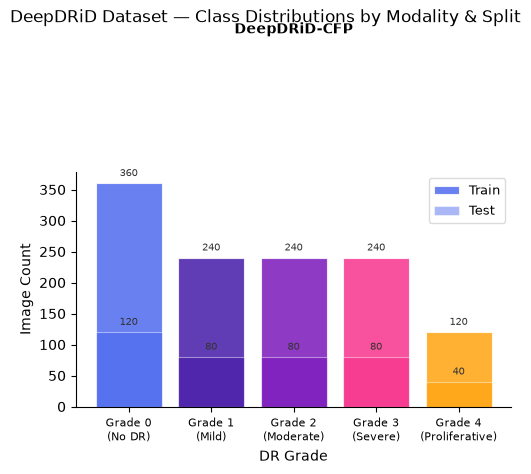

Saved → /home/user/Documents/Mohammadi/workspace/results/figures/dataset_distribution.pdf


In [4]:
def load_manifest(modality: str) -> pd.DataFrame | None:
    path = ROOT / 'data/DeepDRiD' / 'CFP_manifest.csv'
    if not path.exists():
        print(f'  [SKIP] manifest not found: {path}')
        return None
    return pd.read_csv(path)

manifests = {m: load_manifest(m) for m in MODALITIES}

# ── Plot class distributions ──────────────────────────────────────────────────
PALETTE = ['#4361EE', '#3A0CA3', '#7209B7', '#F72585', '#FF9E00',
           '#06D6A0', '#118AB2', '#EF233C']
GRADE_NAMES = ['Grade 0\n(No DR)', 'Grade 1\n(Mild)', 'Grade 2\n(Moderate)',
               'Grade 3\n(Severe)', 'Grade 4\n(Proliferative)']

available = {m: df for m, df in manifests.items() if df is not None}

if available:
    fig, axes = plt.subplots(1, len(available), figsize=(5 * len(available), 4.5),
                             constrained_layout=True)
    if len(available) == 1:
        axes = [axes]

    for ax, (mod, df) in zip(axes, available.items()):
        num_ranks = MODALITIES[mod]['num_ranks']
        for split, style in [('train', 0.8), ('test', 0.45)]:
            sub = df[df['split'] == split]
            counts = sub['grade'].value_counts().sort_index()
            bars = ax.bar(counts.index, counts.values,
                          color=[PALETTE[i] for i in counts.index],
                          alpha=style, edgecolor='white', linewidth=0.8,
                          label=split.capitalize())
            for bar in bars:
                h = bar.get_height()
                ax.text(bar.get_x() + bar.get_width() / 2, h + 8, f'{int(h):,}',
                        ha='center', va='bottom', fontsize=7, color='#333')

        ax.set_title(f'DeepDRiD-{mod}', fontsize=10, fontweight='bold', pad=100)
        ax.set_xlabel('DR Grade', fontsize=10)
        ax.set_ylabel('Image Count', fontsize=10)
        ax.set_xticks(range(num_ranks))
        ax.set_xticklabels(GRADE_NAMES[:num_ranks], fontsize=8)
        ax.legend(fontsize=9, framealpha=0.7)
        ax.spines[['top', 'right']].set_visible(False)
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

    fig.suptitle('DeepDRiD Dataset — Class Distributions by Modality & Split',
                 fontsize=12, y=1.02)
    plt.savefig(FIGURES / 'dataset_distribution.pdf', bbox_inches='tight', dpi=300)
    plt.show()
    print(f'Saved → {FIGURES / "dataset_distribution.pdf"}')
else:
    print('No manifests found. Run scripts/prepare_mmrdr.py first.')

## 4 · Prepare Few-Shot Splits

Generates support/query text files for each modality × k × seed combination.

In [5]:
SPLITS_DIR = ROOT / 'data/DeepDRiD' / 'splits'

def splits_exist(modality: str, k: int, seed: int) -> bool:
    mod_lower = modality.lower()
    sup = SPLITS_DIR / f'{mod_lower}_{k}shot_s{seed}_support.txt'
    qry = SPLITS_DIR / f'{mod_lower}_{k}shot_s{seed}_query.txt'
    return sup.exists() and qry.exists()

to_generate = [
    m for m in MODALITIES
    if manifests.get(m) is not None
    and not all(splits_exist(m, k, s) for k in fs_k for s in SEEDS)
]

if to_generate:
    print('Generating splits for:', to_generate)
    kshots_str = ','.join(str(k) for k in fs_k)
    seeds_str  = ','.join(str(s) for s in SEEDS)
    for mod in to_generate:
        cmd = [
            sys.executable, 'src/data/build_splits.py',
            '--modality', mod,
            '--dataset', 'DeepDRiD',
            '--kshots', kshots_str,
            '--seeds', seeds_str,
        ]
        result = subprocess.run(cmd, capture_output=True, text=True)
        print(result.stdout)
        if result.returncode != 0:
            print('ERROR:', result.stderr)
else:
    print('All splits already exist — skipping generation.')

All splits already exist — skipping generation.


## 5 · Training

### 5a · Single-run helper

This function trains (or skips if already done) one experiment and returns the test metrics.

In [6]:
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint

def run_experiment(
    config_path: str,
    modality: str,
    k_shot: int,
    seed: int,
    variant_name: str = 'Ours (Full)',
    extra_overrides: dict | None = None,
    force_retrain: bool = False,
) -> dict:
    """
    Train and evaluate one experiment.
    Returns a dict of metrics, or loads cached results if they already exist.
    """
    import torch, omegaconf
    import numpy as np
    try:
        torch.serialization.add_safe_globals([
            np._core.multiarray.scalar, np.dtype, getattr(np.dtypes, 'Float64DType', None), getattr(np.dtypes, 'Int64DType', None),
            omegaconf.dictconfig.DictConfig, omegaconf.listconfig.ListConfig
        ])
    except Exception:
        pass

    variant_slug = variant_name.replace(' ', '_').replace('/', '_').replace('(', '').replace(')', '')
    out_dir = RESULTS / variant_slug / f'{modality}_{k_shot}shot_s{seed}'
    stats_file = out_dir / 'test_stats.json'

    if stats_file.exists() and not force_retrain:
        with open(stats_file) as f:
            return json.load(f)

    out_dir.mkdir(parents=True, exist_ok=True)

    overrides = [f'data.k_shot={k_shot}', f'data.seed={seed}', f'train.epochs={EPOCHS}']
    if extra_overrides:
        overrides += [f'{k}={v}' for k, v in extra_overrides.items()]

    cfg = load_config(config_path, overrides)
    pl.seed_everything(seed, workers=True)

    datamodule = FewShotDataModule(cfg)
    model = FewShotOrdinalRunner(cfg)

    monitor  = cfg.train.get('early_stopping_monitor', 'val_qwk')
    mode     = cfg.train.get('early_stopping_mode', 'max')
    patience = cfg.train.get('early_stopping_patience', 30)

    checkpoint_callback = ModelCheckpoint(
        dirpath=str(out_dir), filename='best',
        monitor=monitor, mode=mode, save_top_k=1, save_last=True
    )
    callbacks = [
        EarlyStopping(monitor=monitor, patience=patience, mode=mode, verbose=False),
        checkpoint_callback,
    ]

    try:
        prec = 'bf16-mixed' if torch.cuda.is_bf16_supported() else '32-true'
    except Exception:
        prec = '32-true'

    trainer = pl.Trainer(
        max_epochs=EPOCHS if k_shot != 0 else 0,
        accelerator='auto', devices=1,
        precision=prec,
        gradient_clip_val=1.0,
        callbacks=callbacks,
        log_every_n_steps=1,
        enable_checkpointing=True,
        enable_progress_bar=True,
        logger=True,
        enable_model_summary=False,
    )

    if k_shot != 0:
        last_ckpt = out_dir / 'last.ckpt'
        if last_ckpt.exists():
            print(f'Resuming from {last_ckpt}')
            trainer.fit(model, datamodule=datamodule, ckpt_path=str(last_ckpt), weights_only=False)
        else:
            trainer.fit(model, datamodule=datamodule)
        
        # Test with the best checkpoint
        best_ckpt = checkpoint_callback.best_model_path
        if best_ckpt:
            model = FewShotOrdinalRunner.load_from_checkpoint(best_ckpt, cfg=cfg, weights_only=False)

    trainer.test(model, datamodule=datamodule, verbose=False)

    metrics = {k: float(v) for k, v in model.latest_metrics.items()}
    with open(stats_file, 'w') as f:
        json.dump(metrics, f, indent=4)

    return metrics

print('run_experiment() helper defined.')


run_experiment() helper defined.


### 5b · Run Full Experiment Grid (Main Model)

> **Tip**: Set `MODALITIES_TO_RUN` and `K_SHOTS_TO_RUN` to subset the grid for a quick test.

In [7]:
# ── Subset these to run only part of the grid ─────────────────────────────────
MODALITIES_TO_RUN = list(MODALITIES)      # e.g. ['CFP'] for a single modality
K_SHOTS_TO_RUN = [-1, 0, 1, 2, 4, 8, 16, 32] #K_SHOTS               # e.g. [0, 4] for quick test
SEEDS_TO_RUN      = SEEDS

# ── Collect all results ───────────────────────────────────────────────────────
all_results = []  # list of dicts

total = len(MODALITIES_TO_RUN) * len(K_SHOTS_TO_RUN) * (
    1 if 0 in K_SHOTS_TO_RUN else 0  # zero-shot = 1 run per modality
) + len(MODALITIES_TO_RUN) * len([k for k in K_SHOTS_TO_RUN if k > 0]) * len(SEEDS_TO_RUN)

pbar = tqdm(total=total, desc='Experiments')

seen_zeroshot = set()  # zero-shot only once per modality

for mod in MODALITIES_TO_RUN:
    cfg_path = MODALITIES[mod]['config']

    for k in K_SHOTS_TO_RUN:
        seeds_for_k = [1] if k == 0 else SEEDS_TO_RUN  # zero-shot: single deterministic run

        for seed in seeds_for_k:
            if k == 0 and mod in seen_zeroshot:
                continue
            if k == 0:
                seen_zeroshot.add(mod)

            pbar.set_postfix({'mod': mod, 'k': k, 'seed': seed})

            metrics = run_experiment(
                config_path=cfg_path,
                modality=mod,
                k_shot=k,
                seed=seed,
                variant_name='Ours (Full)',
            )

            all_results.append({
                'Variant':  'Ours (Full)',
                'Modality': mod,
                'k':        k,
                'Seed':     seed,
                **metrics,
            })
            pbar.update(1)

pbar.close()

df_results = pd.DataFrame(all_results)
print('\nDone! Shape:', df_results.shape)
df_results.head(35)

Experiments:  85%|████████▍ | 22/26 [00:00<00:00, 2166.63it/s, mod=CFP, k=32, seed=3]


Done! Shape: (22, 10)


,Variant,Modality,k,Seed,qwk,mae,f1,auc,acc,los
0,Ours (Full),CFP,-1,1,0.873997,0.3525,0.625716,0.887743,0.6950,1.0000
1,Ours (Full),CFP,-1,2,0.867893,0.3575,0.624274,0.887831,0.6950,1.0000
2,Ours (Full),CFP,-1,3,0.867460,0.3800,0.619586,0.888088,0.6700,1.0000
3,Ours (Full),CFP,0,1,-0.006751,1.3375,0.134510,0.586036,0.2400,0.8575
4,Ours (Full),CFP,1,1,0.012446,1.5500,0.095138,0.530680,0.2125,1.0000
5,Ours (Full),CFP,1,2,0.091377,1.1875,0.097185,0.510483,0.2100,1.0000
6,Ours (Full),CFP,1,3,0.302294,1.1650,0.277082,0.565936,0.3300,1.0000
7,Ours (Full),CFP,2,1,0.523740,0.9050,0.351357,0.682176,0.3750,1.0000
8,Ours (Full),CFP,2,2,0.096606,1.3875,0.151775,0.503055,0.2125,1.0000
9,Ours (Full),CFP,2,3,0.258390,1.1775,0.217952,0.611560,0.2450,1.0000


### 5c · Run Ablation Study

Runs the configured ablation variants across CFP and the selected k-shot regimes for all seeds.


In [8]:
RUN_ABLATIONS   = True    # set False to skip
ABLATION_MOD    = 'CFP'
ABLATION_K_SHOTS = [-1, 0, 1, 2, 4, 8, 16, 32]
ABLATION_SEEDS  = SEEDS

ablation_results = []

if RUN_ABLATIONS:
    cfg_path = MODALITIES[ABLATION_MOD]['config']
    total_abl = len(ABLATIONS) * len(ABLATION_K_SHOTS) * len(ABLATION_SEEDS)
    pbar = tqdm(total=total_abl, desc='Ablations')

    for k_shot in ABLATION_K_SHOTS:
        for variant_name, overrides in ABLATIONS.items():
            for seed in ABLATION_SEEDS:
                pbar.set_postfix({'variant': variant_name, 'k': k_shot, 'seed': seed})
                metrics = run_experiment(
                    config_path=cfg_path,
                    modality=ABLATION_MOD,
                    k_shot=k_shot,
                    seed=seed,
                    variant_name=variant_name,
                    extra_overrides=overrides,
                )
                ablation_results.append({
                    'Variant':  variant_name,
                    'Modality': ABLATION_MOD,
                    'k':        k_shot,
                    'Seed':     seed,
                    **metrics,
                })
                pbar.update(1)
    pbar.close()

df_ablation = pd.DataFrame(ablation_results)
print('Ablation shape:', df_ablation.shape)
df_ablation.head()


Ablations:  99%|█████████▉| 214/216 [00:00<00:00, 2127.84it/s, variant=baseline, k=32, seed=2]          Seed set to 2


Trainable parameters: 25306625
Resuming from /home/user/Documents/Mohammadi/workspace/results/baseline/CFP_32shot_s2/last.ckpt


Ablations:  99%|█████████▉| 214/216 [00:19<00:00, 2127.84it/s, variant=baseline, k=32, seed=2]

Trainable parameters: 25306625


Ablations: 100%|█████████▉| 215/216 [26:11<00:10, 10.40s/it, variant=baseline, k=32, seed=3]  Seed set to 3


Trainable parameters: 25306625


Trainable parameters: 25306625


Ablations: 100%|██████████| 216/216 [53:11<00:00, 14.77s/it, variant=baseline, k=32, seed=3]

Ablation shape: (216, 10)


,Variant,Modality,k,Seed,qwk,mae,f1,auc,acc,los
0,Ours (Full),CFP,-1,1,0.873997,0.3525,0.625716,0.887743,0.6950,1.0
1,Ours (Full),CFP,-1,2,0.867893,0.3575,0.624274,0.887831,0.6950,1.0
2,Ours (Full),CFP,-1,3,0.867460,0.3800,0.619586,0.888088,0.6700,1.0
3,w/o RankFormer,CFP,-1,1,0.864169,0.3600,0.626631,0.864167,0.6925,1.0
4,w/o RankFormer,CFP,-1,2,0.865588,0.3525,0.645968,0.886439,0.7025,1.0


## 6 · Aggregate & Display Results Table

In [9]:
METRICS = ['qwk', 'mae', 'f1', 'auc', 'acc', 'los']
METRIC_LABELS = {'qwk': 'QWK↑', 'mae': 'MAE↓', 'f1': 'Macro-F1↑',
                 'auc': 'AUC↑', 'acc': 'Accuracy↑', 'los': 'LOS↑'}

def aggregate(df: pd.DataFrame, group_cols: list[str]) -> pd.DataFrame:
    """Compute mean ± std per group."""
    rows = []
    for keys, grp in df.groupby(group_cols):
        row = dict(zip(group_cols, keys if isinstance(keys, tuple) else [keys]))
        for m in METRICS:
            if m in grp.columns:
                row[f'{m}_mean'] = grp[m].mean()
                row[f'{m}_std']  = grp[m].std(ddof=1) if len(grp) > 1 else 0.0
                row[m] = f"{grp[m].mean():.4f} ± {row[f'{m}_std']:.4f}"
        rows.append(row)
    return pd.DataFrame(rows)

# ── Main results table ────────────────────────────────────────────────────────
if not df_results.empty:
    df_agg = aggregate(df_results, ['Variant', 'Modality', 'k'])
    display_cols = ['Variant', 'Modality', 'k'] + METRICS
    display(df_agg[display_cols].sort_values(['Modality', 'k']).to_string(index=False))

    # Save
    df_agg.to_csv(RESULTS / 'main_results.csv', index=False)
    print(f'\nSaved → {RESULTS / "main_results.csv"}')

'    Variant Modality  k              qwk             mae              f1             auc             acc             los\nOurs (Full)      CFP -1  0.8698 ± 0.0037 0.3633 ± 0.0146 0.6232 ± 0.0032 0.8879 ± 0.0002 0.6867 ± 0.0144 1.0000 ± 0.0000\nOurs (Full)      CFP  0 -0.0068 ± 0.0000 1.3375 ± 0.0000 0.1345 ± 0.0000 0.5860 ± 0.0000 0.2400 ± 0.0000 0.8575 ± 0.0000\nOurs (Full)      CFP  1  0.1354 ± 0.1498 1.3008 ± 0.2161 0.1565 ± 0.1045 0.5357 ± 0.0281 0.2508 ± 0.0686 1.0000 ± 0.0000\nOurs (Full)      CFP  2  0.2929 ± 0.2156 1.1567 ± 0.2419 0.2404 ± 0.1017 0.5989 ± 0.0902 0.2775 ± 0.0860 1.0000 ± 0.0000\nOurs (Full)      CFP  4  0.2974 ± 0.2385 1.2617 ± 0.5150 0.2397 ± 0.1035 0.6195 ± 0.1187 0.2917 ± 0.1156 1.0000 ± 0.0000\nOurs (Full)      CFP  8  0.6291 ± 0.0941 0.7708 ± 0.1130 0.4171 ± 0.0149 0.7516 ± 0.0311 0.4667 ± 0.0292 1.0000 ± 0.0000\nOurs (Full)      CFP 16  0.6961 ± 0.0219 0.6667 ± 0.0887 0.4493 ± 0.0525 0.7905 ± 0.0170 0.5117 ± 0.0605 1.0000 ± 0.0000\nOurs (Full)      CFP 32


Saved → /home/user/Documents/Mohammadi/workspace/results/main_results.csv


## 7 · Paper-Quality Plots

### 7a · k-Shot Performance Curves

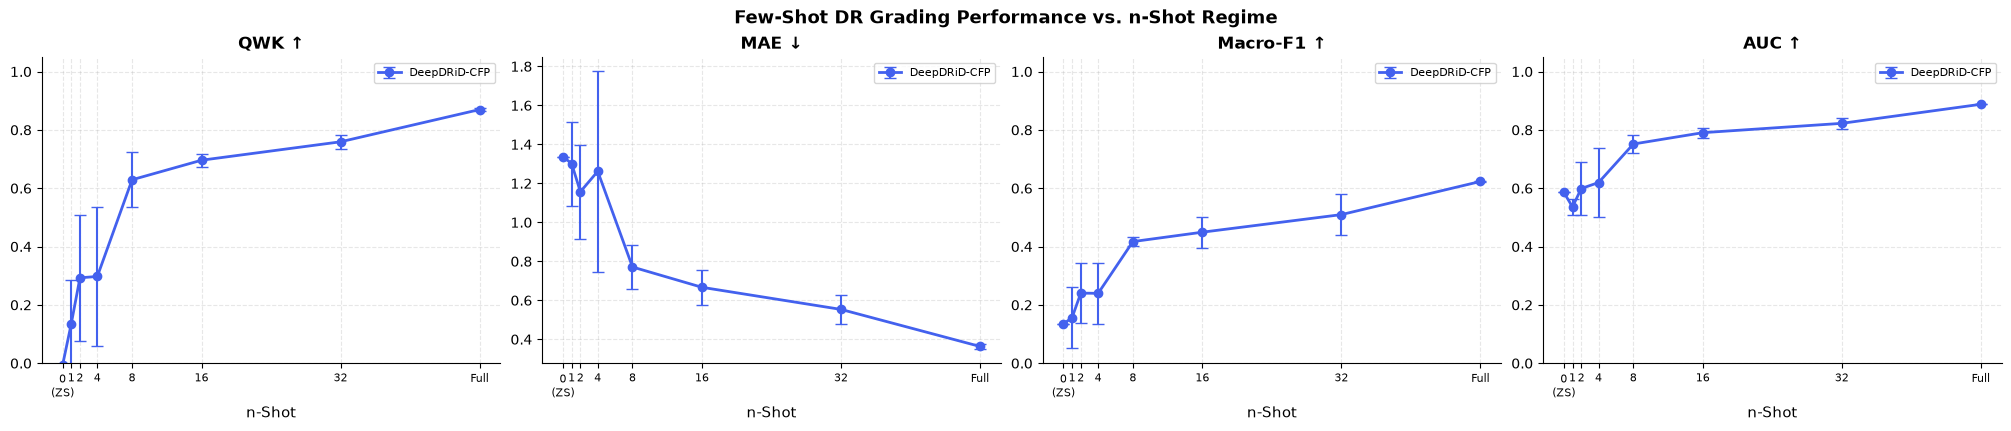

Saved → /home/user/Documents/Mohammadi/workspace/results/figures/kshot_curves.pdf


In [10]:
# ── Style ─────────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--',
})

MOD_COLORS  = {'CFP': '#4361EE', 'OCT': '#F72585', 'UWF': '#06D6A0'}
MOD_MARKERS = {'CFP': 'o',       'OCT': 's',       'UWF': '^'}

PLOT_METRICS = ['qwk', 'mae', 'f1', 'auc']
PLOT_LABELS  = ['QWK ↑', 'MAE ↓', 'Macro-F1 ↑', 'AUC ↑']

if not df_results.empty:
    df_agg = aggregate(df_results, ['Variant', 'Modality', 'k'])
    main = df_agg[df_agg['Variant'] == 'Ours (Full)']

    fig, axes = plt.subplots(1, len(PLOT_METRICS), figsize=(5 * len(PLOT_METRICS), 4.2),
                             constrained_layout=True)

    for ax, metric, label in zip(axes, PLOT_METRICS, PLOT_LABELS):
        for mod in MODALITIES_TO_RUN:
            sub = main[main['Modality'] == mod].assign(k_plot=lambda x: np.where(x['k'] == -1, 48, x['k'])).sort_values('k_plot')
            if sub.empty or f'{metric}_mean' not in sub.columns:
                continue
            mu  = sub[f'{metric}_mean'].values
            std = sub[f'{metric}_std'].values
            ks  = sub['k'].values
            ks_plot = np.where(ks == -1, 48, ks)

            # Replaced fill_between with errorbar to match the style of the uploaded plot
            ax.errorbar(ks_plot, mu, yerr=std, marker=MOD_MARKERS[mod], color=MOD_COLORS[mod],
                        linewidth=2, markersize=6, capsize=4, elinewidth=1.5,
                        label=f'DeepDRiD-{mod}')

        ax.set_title(label, fontsize=12, fontweight='bold')
        ax.set_xlabel('n-Shot', fontsize=11)
        xticks_pos = [48 if k == -1 else k for k in K_SHOTS_TO_RUN]
        ax.set_xticks(xticks_pos)
        ax.set_xticklabels([str(k) if k > 0 else '0\n(ZS)' if k == 0 else 'Full' for k in K_SHOTS_TO_RUN], fontsize=8)
        if metric in ('qwk', 'f1', 'auc', 'acc', 'los'):
            ax.set_ylim(0, 1.05)
        ax.legend(fontsize=8, framealpha=0.8)

    fig.suptitle('Few-Shot DR Grading Performance vs. n-Shot Regime',
                 fontsize=13, fontweight='bold')
    plt.savefig(FIGURES / 'kshot_curves.pdf', bbox_inches='tight', dpi=300)
    plt.savefig(FIGURES / 'kshot_curves.png', bbox_inches='tight', dpi=300)
    plt.show()
    print(f'Saved → {FIGURES / "kshot_curves.pdf"}')
else:
    print('No results yet — run Section 5 first.')


### 7b · Per-Modality Bar Chart (Selected k-Shot Regimes)


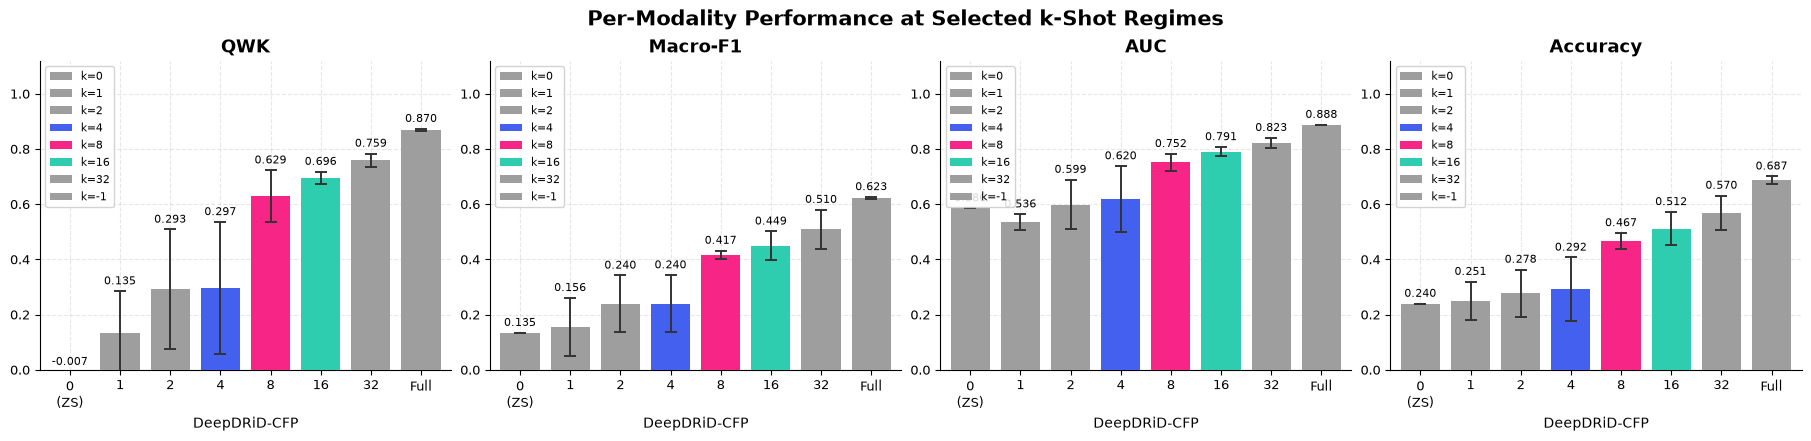

Saved → /home/user/Documents/Mohammadi/workspace/results/figures/modality_bar.pdf


In [11]:
# ── 7b · Per-Modality Bar Chart ───────────────────────────────────────────────
# Reproduces the bar-chart layout shown in the reference figure:
# one bar per k-shot regime, four metrics, mean ± std error bars.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.30,
    'grid.linestyle': '--',
})

# Use CFP for this figure. Change to 'OCT' or 'UWF' when those
# modalities are present in df_results.
BAR_MOD = 'CFP'

# The reference figure excludes the internal -1 / "Full" regime.
SELECTED_K = [0, 1, 2, 4, 8, 16, 32, -1]

# The reference figure uses these four metrics.
BAR_METRICS = ['qwk', 'f1', 'auc', 'acc']
BAR_LABELS = ['QWK', 'Macro-F1', 'AUC', 'Accuracy']

# Match the reference colours:
# k=4 -> blue, k=8 -> pink, k=16 -> green, all other k -> grey.
K_COLORS = {
    4:  '#4361EE',
    8:  '#F72585',
    16: '#2ECDB0',
}
DEFAULT_BAR_COLOR = '#9E9E9E'

if df_results.empty:
    print('No results yet — run Section 5b first.')
else:
    # Aggregate over seeds for each Variant / Modality / k.
    df_bar = aggregate(df_results, ['Variant', 'Modality', 'k'])

    main = df_bar[
        (df_bar['Variant'] == 'Ours (Full)') &
        (df_bar['Modality'] == BAR_MOD) &
        (df_bar['k'].isin(SELECTED_K))
    ].copy()

    # Keep the requested k-shot order, not alphabetical/numeric dataframe order.
    main['k'] = pd.Categorical(main['k'], categories=SELECTED_K, ordered=True)
    main = main.sort_values('k')

    if main.empty:
        print(f'No Ours (Full) results found for modality={BAR_MOD}.')
    else:
        missing_k = [k for k in SELECTED_K if k not in main['k'].tolist()]
        if missing_k:
            print(f'Warning: missing k-shot regimes: {missing_k}')

        fig, axes = plt.subplots(
            1, len(BAR_METRICS),
            figsize=(18.0, 4.3),
            sharey=False,
            constrained_layout=True
        )

        x = np.arange(len(main))
        k_values = main['k'].astype(int).to_numpy()
        bar_colors = [K_COLORS.get(k, DEFAULT_BAR_COLOR) for k in k_values]

        for ax, metric, title in zip(axes, BAR_METRICS, BAR_LABELS):
            mean_col = f'{metric}_mean'
            std_col = f'{metric}_std'

            if mean_col not in main.columns:
                ax.set_visible(False)
                continue

            means = main[mean_col].astype(float).to_numpy()
            stds = (
                main[std_col].astype(float).to_numpy()
                if std_col in main.columns
                else np.zeros_like(means)
            )

            bars = ax.bar(
                x, means,
                yerr=stds,
                width=0.78,
                color=bar_colors,
                edgecolor='none',
                capsize=4,
                error_kw={
                    'elinewidth': 1.4,
                    'capthick': 1.4,
                    'ecolor': '#333333',
                },
                zorder=3,
            )

            # Numeric labels above each bar.
            for xpos, bar, mean, std in zip(x, bars, means, stds):
                y_text = mean + std + 0.015
                ax.text(
                    xpos, y_text, f'{mean:.3f}',
                    ha='center', va='bottom',
                    fontsize=8
                )

            ax.set_title(title, fontsize=13, fontweight='bold')
            # The reference figure uses the modality name as the x-axis label.
            # k values are identified by the legend rather than x tick labels.
            ax.set_xticks(x)
            ax.set_xticklabels([str(k) if k > 0 else '0\n(ZS)' if k == 0 else 'Full' for k in k_values], fontsize=9)
            ax.set_xlabel(f'{DATASET}-{BAR_MOD}', fontsize=10)

            # All four metrics in this figure are bounded by [0, 1].
            ax.set_ylim(0, 1.12)
            ax.set_xlim(-0.6, len(x) - 0.4)
            ax.tick_params(axis='y', labelsize=9)
            ax.grid(axis='y', zorder=0)

        # Legend is keyed by k-shot, matching the reference figure.
        legend_handles = [
            Patch(facecolor=K_COLORS.get(k, DEFAULT_BAR_COLOR),
                  edgecolor='none', label=f'k={k}')
            for k in SELECTED_K
        ]
        for ax in axes:
            ax.legend(
                handles=legend_handles,
                fontsize=8,
                framealpha=0.85,
                loc='upper left'
            )

        fig.suptitle(
            'Per-Modality Performance at Selected k-Shot Regimes',
            fontsize=15,
            fontweight='bold'
        )
        plt.savefig(
            FIGURES / 'modality_bar.pdf',
            bbox_inches='tight',
            dpi=300
        )
        plt.savefig(
            FIGURES / 'modality_bar.png',
            bbox_inches='tight',
            dpi=300
        )
        plt.show()
        print(f'Saved → {FIGURES / "modality_bar.pdf"}')


### 7c · Confusion Matrix (best seed, chosen modality & k)

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def get_predictions(config_path, modality, k_shot, seed, variant_name='Ours (Full)', extra_overrides=None):
    """Re-run test pass and collect raw predictions for a confusion matrix."""
    variant_slug = variant_name.replace(' ', '_').replace('/', '_').replace('(', '').replace(')', '')
    out_dir = RESULTS / variant_slug / f'{modality}_{k_shot}shot_s{seed}'
    ckpt    = out_dir / 'best.ckpt'

    overrides = [f'data.k_shot={k_shot}', f'data.seed={seed}', f'train.epochs={EPOCHS}']
    if extra_overrides:
        overrides += [f'{k}={v}' for k, v in extra_overrides.items()]

    cfg = load_config(config_path, overrides)
    datamodule = FewShotDataModule(cfg)

    if ckpt.exists():
        import omegaconf
        try: torch.serialization.add_safe_globals([omegaconf.dictconfig.DictConfig])
        except: pass
        model = FewShotOrdinalRunner.load_from_checkpoint(str(ckpt), cfg=cfg, weights_only=False)
    else:
        model = FewShotOrdinalRunner(cfg)

    datamodule.setup('test')
    loader = datamodule.test_dataloader()
    all_preds, all_targets = [], []
    model.eval().to(DEVICE)
    with torch.no_grad():
        for batch in loader:
            imgs, labels, _, _ = batch
            imgs = imgs.to(DEVICE)
            img_f, txt_f = model(imgs)
            scale = model.clip_model.logit_scale.exp()
            sim   = scale * img_f @ txt_f.T
            if model.sms is not None:
                sim = model.sms(sim)
            preds = F.softmax(sim, dim=-1).argmax(dim=-1).cpu()
            all_preds.append(preds)
            all_targets.append(labels)
            
    res_t = torch.cat(all_targets).numpy()
    res_p = torch.cat(all_preds).numpy()
    
    # Move model to CPU to forcefully free GPU memory even if references leak
    model.cpu()
    
    # Robust cleanup
    del model
    del datamodule
    del loader
    if 'imgs' in locals():
        del imgs, labels, img_f, txt_f, sim, preds, scale
    
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        
    return res_t, res_p

# Determine what to run (falling back to all if not explicitly subsetted)
mods_to_run = locals().get('MODALITIES_TO_RUN', list(MODALITIES.keys()))
k_shots_to_run = locals().get('K_SHOTS_TO_RUN', K_SHOTS)

# Loop over all ablations, modalities, k-shots, and seeds
for variant_name, overrides in ABLATIONS.items():
    variant_slug = variant_name.replace(' ', '_').replace('/', '_').replace('(', '').replace(')', '')
    
    for mod in mods_to_run:
        cfg_path = MODALITIES[mod]['config']
        num_ranks = MODALITIES[mod]['num_ranks']
        
        for k in k_shots_to_run:
            for seed in SEEDS:
                print(f"Generating CM for: {variant_name} | {mod} | k={k} | seed={seed}")
                
                targets, preds = get_predictions(cfg_path, mod, k, seed, variant_name, overrides)

                fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

                # 1. Raw count CM
                cm_counts = confusion_matrix(targets, preds)
                disp = ConfusionMatrixDisplay(cm_counts,
                                              display_labels=[f'G{i}' for i in range(num_ranks)])
                disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
                axes[0].set_title(f'Confusion Matrix (counts)\n{variant_name} - DeepDRiD-{mod}  k={k}  seed={seed}',
                                  fontsize=11, fontweight='bold')
                axes[0].grid(False) # Ensure grid is off

                # 2. Row-normalised CM (Added np.maximum to prevent div by zero just in case)
                row_sums = np.maximum(cm_counts.sum(axis=1, keepdims=True), 1)
                cm_norm = cm_counts.astype(float) / row_sums
                disp2 = ConfusionMatrixDisplay(np.round(cm_norm, 2),
                                               display_labels=[f'G{i}' for i in range(num_ranks)])
                disp2.plot(ax=axes[1], cmap='Purples', colorbar=False)
                axes[1].set_title(f'Confusion Matrix (row-normalised)\n{variant_name} - DeepDRiD-{mod}  k={k}  seed={seed}',
                                  fontsize=11, fontweight='bold')
                axes[1].grid(False) # Ensure grid is off

                # Save figure in a structured directory
                out_dir = FIGURES / variant_slug
                out_dir.mkdir(parents=True, exist_ok=True)
                save_path = out_dir / f'confusion_{mod}_k{k}_s{seed}.pdf'
                
                plt.savefig(save_path, bbox_inches='tight', dpi=300)
                plt.close(fig)
                print(f'Saved → {save_path}\n' + '-'*60)


Generating CM for: Ours (Full) | CFP | k=-1 | seed=1
Trainable parameters: 27546545
Saved → /home/user/Documents/Mohammadi/workspace/results/figures/Ours_Full/confusion_CFP_k-1_s1.pdf
------------------------------------------------------------
Generating CM for: Ours (Full) | CFP | k=-1 | seed=2
Trainable parameters: 27546545
Saved → /home/user/Documents/Mohammadi/workspace/results/figures/Ours_Full/confusion_CFP_k-1_s2.pdf
------------------------------------------------------------
Generating CM for: Ours (Full) | CFP | k=-1 | seed=3
Trainable parameters: 27546545
Saved → /home/user/Documents/Mohammadi/workspace/results/figures/Ours_Full/confusion_CFP_k-1_s3.pdf
------------------------------------------------------------
Generating CM for: Ours (Full) | CFP | k=0 | seed=1
Trainable parameters: 27546545
Saved → /home/user/Documents/Mohammadi/workspace/results/figures/Ours_Full/confusion_CFP_k0_s1.pdf
------------------------------------------------------------
Generating CM for: Our

### 7d · Ablation Study Table & Plot (k = 16)


Ablation Study — DeepDRiD-CFP, k=8 (mean ± std over seeds)


,Variant,qwk,mae,f1,auc,acc,los
0,Ours (Full),0.6291 ± 0.0941,0.7708 ± 0.1130,0.4171 ± 0.0149,0.7516 ± 0.0311,0.4667 ± 0.0292,1.0000 ± 0.0000
1,baseline,0.5854 ± 0.0546,0.8542 ± 0.0924,0.3798 ± 0.0492,0.7208 ± 0.0401,0.4392 ± 0.0488,0.8775 ± 0.0597
2,w/o RankFormer,0.7096 ± 0.0140,0.6542 ± 0.0347,0.4434 ± 0.0241,0.7963 ± 0.0129,0.5108 ± 0.0146,1.0000 ± 0.0000
3,w/o SMS,0.6444 ± 0.0486,0.7658 ± 0.0734,0.4152 ± 0.0172,0.7663 ± 0.0268,0.4808 ± 0.0279,0.9783 ± 0.0142
4,w/o PairwiseLoss,0.6156 ± 0.0967,0.8267 ± 0.0975,0.3859 ± 0.0216,0.7488 ± 0.0159,0.4417 ± 0.0202,1.0000 ± 0.0000
5,w/o RankingLoss,0.6305 ± 0.0421,0.8317 ± 0.0388,0.3831 ± 0.0110,0.7310 ± 0.0099,0.4517 ± 0.0128,1.0000 ± 0.0000
6,w/o LoRA,0.4151 ± 0.0990,1.0142 ± 0.1088,0.2622 ± 0.0527,0.7122 ± 0.0402,0.3150 ± 0.0467,1.0000 ± 0.0000
7,just LoRA,0.7084 ± 0.0362,0.6733 ± 0.0559,0.4308 ± 0.0260,0.7781 ± 0.0195,0.5025 ± 0.0347,0.9733 ± 0.0113
8,LoRA + RankingLoss,0.6969 ± 0.0087,0.6750 ± 0.0434,0.4559 ± 0.0252,0.7886 ± 0.0200,0.5117 ± 0.0279,0.9725 ± 0.0050


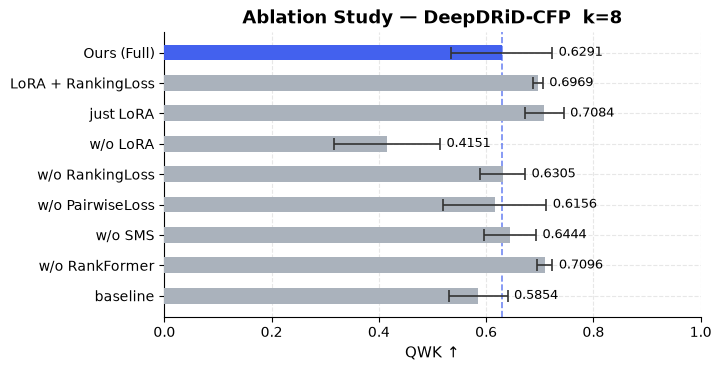

Saved → /home/user/Documents/Mohammadi/workspace/results/figures/ablation_qwk.pdf


In [21]:
# ── 7d · Ablation Study Table & Plot ─────────────────────────────────────────
# Table: mean ± std over seeds at one selected k.
# Plot : horizontal QWK bar chart matching the reference ablation figure.

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.30,
    'grid.linestyle': '--',
})

# Reference figure is for CFP at k=16 and uses QWK.
ABLATION_MOD_PLOT = 'CFP'
ABLATION_K_PLOT = 8
ABLATION_METRIC_PLOT = 'qwk'

# Set this to None to plot every variant in ABLATIONS.
# The three entries below reproduce the reference figure.
ABLATION_VARIANTS_TO_PLOT = [
    'Ours (Full)',
    'baseline',
    'w/o RankFormer',
    'w/o SMS',
    'w/o PairwiseLoss',
    'w/o RankingLoss',
    'w/o LoRA',
    'just LoRA',
    'LoRA + RankingLoss'
]

if df_ablation.empty:
    print('No ablation results yet — run Section 5c first.')
else:
    df_abl_agg = aggregate(
        df_ablation,
        ['Variant', 'Modality', 'k']
    )

    # Restrict the table to the selected modality and k.
    table = df_abl_agg[
        (df_abl_agg['Modality'] == ABLATION_MOD_PLOT) &
        (df_abl_agg['k'] == ABLATION_K_PLOT)
    ].copy()

    if ABLATION_VARIANTS_TO_PLOT is not None:
        table = table[
            table['Variant'].isin(ABLATION_VARIANTS_TO_PLOT)
        ].copy()

    # Preserve the requested display order, with Ours (Full) last in the plot.
    preferred_order = [
        v for v in (ABLATION_VARIANTS_TO_PLOT or list(ABLATIONS.keys()))
        if v in table['Variant'].tolist()
    ]

    table['_order'] = table['Variant'].map(
        {v: i for i, v in enumerate(preferred_order)}
    )
    table = table.sort_values('_order').drop(columns='_order')

    if table.empty:
        print(
            f'No ablation data found for '
            f'{ABLATION_MOD_PLOT}, k={ABLATION_K_PLOT}.'
        )
    else:
        # ── Table ────────────────────────────────────────────────────────────
        display_cols = [
            'Variant',
            'qwk', 'mae', 'f1', 'auc', 'acc', 'los'
        ]
        display_cols = [c for c in display_cols if c in table.columns]

        print(
            f'Ablation Study — {DATASET}-{ABLATION_MOD_PLOT}, '
            f'k={ABLATION_K_PLOT} (mean ± std over seeds)'
        )
        print('=' * 90)
        display(table[display_cols].reset_index(drop=True))

        # Save the selected-k table.
        table[display_cols].to_csv(
            RESULTS / 'ablation_results_k16.csv',
            index=False
        )

        # ── Horizontal QWK plot ──────────────────────────────────────────────
        metric = ABLATION_METRIC_PLOT
        mean_col = f'{metric}_mean'
        std_col = f'{metric}_std'

        plot_df = table[['Variant', mean_col, std_col]].copy()

        # Put Ours (Full) at the bottom, as in the reference figure.
        plot_order = [
            v for v in plot_df['Variant'].tolist()
            if v != 'Ours (Full)'
        ]
        if 'Ours (Full)' in plot_df['Variant'].tolist():
            plot_order.append('Ours (Full)')

        plot_df = (
            plot_df.set_index('Variant')
                   .loc[plot_order]
                   .reset_index()
        )

        y = np.arange(len(plot_df))
        means = plot_df[mean_col].astype(float).to_numpy()
        stds = plot_df[std_col].astype(float).to_numpy()

        # Grey for ablations, blue for the full model.
        colors = [
            '#4361EE' if v == 'Ours (Full)' else '#AAB2BC'
            for v in plot_df['Variant']
        ]

        fig, ax = plt.subplots(
            figsize=(7.1, 3.6),
            constrained_layout=True
        )

        ax.barh(
            y, means,
            xerr=stds,
            color=colors,
            edgecolor='none',
            height=0.52,
            capsize=4,
            error_kw={
                'elinewidth': 1.2,
                'capthick': 1.2,
                'ecolor': '#333333',
            },
            zorder=3,
        )

        # Reference line at the full-model QWK.
        full_rows = plot_df[plot_df['Variant'] == 'Ours (Full)']
        if not full_rows.empty:
            full_qwk = float(full_rows[mean_col].iloc[0])
            ax.axvline(
                full_qwk,
                color='#4361EE',
                linestyle='--',
                linewidth=1.2,
                alpha=0.75,
                zorder=2
            )

        # Numeric labels to the right of each bar.
        x_max = max(1.0, float(np.max(means + stds)) + 0.10)
        for yi, mean, std in zip(y, means, stds):
            ax.text(
                mean + std + 0.012,
                yi,
                f'{mean:.4f}',
                va='center',
                ha='left',
                fontsize=9
            )

        ax.set_yticks(y)
        ax.set_yticklabels(plot_df['Variant'], fontsize=10)
        ax.set_xlabel('QWK ↑', fontsize=11)
        ax.set_xlim(0, min(1.0, x_max))
        ax.grid(axis='x', zorder=0)

        ax.set_title(
            f'Ablation Study — {DATASET}-{ABLATION_MOD_PLOT}  '
            f'k={ABLATION_K_PLOT}',
            fontsize=13,
            fontweight='bold'
        )

        plt.savefig(
            FIGURES / 'ablation_qwk.pdf',
            bbox_inches='tight',
            dpi=300
        )
        plt.show()
        print(f'Saved → {FIGURES / "ablation_qwk.pdf"}')


Ablation Study — DeepDRiD-CFP, k=16 (mean ± std over seeds)


,Variant,qwk,mae,f1,auc,acc,los
0,Ours (Full),0.6961 ± 0.0219,0.6667 ± 0.0887,0.4493 ± 0.0525,0.7905 ± 0.0170,0.5117 ± 0.0605,1.0000 ± 0.0000
1,baseline,0.6147 ± 0.0671,0.7817 ± 0.1000,0.4126 ± 0.0427,0.7530 ± 0.0325,0.4483 ± 0.0618,0.8758 ± 0.0275
2,w/o RankFormer,0.7336 ± 0.0282,0.6075 ± 0.0631,0.4908 ± 0.0334,0.8109 ± 0.0338,0.5508 ± 0.0419,1.0000 ± 0.0000
3,w/o SMS,0.6901 ± 0.0334,0.6750 ± 0.1050,0.4556 ± 0.0668,0.7886 ± 0.0199,0.5108 ± 0.0586,0.9742 ± 0.0153
4,w/o PairwiseLoss,0.7024 ± 0.0157,0.6450 ± 0.0458,0.4469 ± 0.0388,0.7965 ± 0.0161,0.5200 ± 0.0218,1.0000 ± 0.0000
5,w/o RankingLoss,0.6729 ± 0.0405,0.7192 ± 0.0878,0.4323 ± 0.0320,0.7648 ± 0.0271,0.4967 ± 0.0284,1.0000 ± 0.0000
6,w/o LoRA,0.4896 ± 0.2107,0.8925 ± 0.1682,0.2941 ± 0.1416,0.6606 ± 0.1700,0.3392 ± 0.0955,1.0000 ± 0.0000
7,just LoRA,0.6989 ± 0.0347,0.6283 ± 0.0580,0.5000 ± 0.0213,0.8129 ± 0.0212,0.5533 ± 0.0216,0.9825 ± 0.0066
8,LoRA + RankingLoss,0.7147 ± 0.0294,0.6067 ± 0.0438,0.4817 ± 0.0333,0.8135 ± 0.0139,0.5400 ± 0.0370,0.9708 ± 0.0123


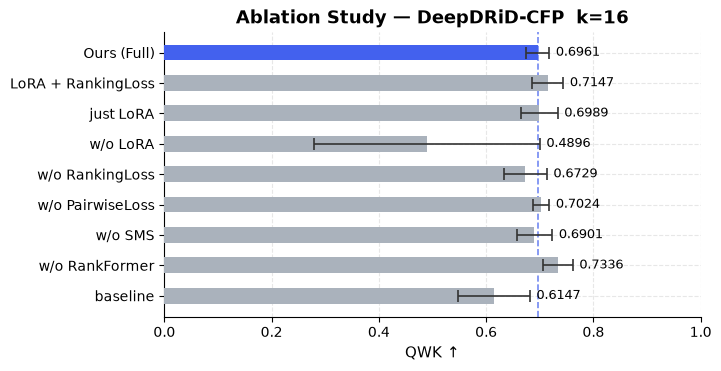

Saved → /home/user/Documents/Mohammadi/workspace/results/figures/ablation_qwk.pdf


In [22]:
# ── 7d · Ablation Study Table & Plot ─────────────────────────────────────────
# Table: mean ± std over seeds at one selected k.
# Plot : horizontal QWK bar chart matching the reference ablation figure.

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.30,
    'grid.linestyle': '--',
})

# Reference figure is for CFP at k=16 and uses QWK.
ABLATION_MOD_PLOT = 'CFP'
ABLATION_K_PLOT = 16
ABLATION_METRIC_PLOT = 'qwk'

# Set this to None to plot every variant in ABLATIONS.
# The three entries below reproduce the reference figure.
ABLATION_VARIANTS_TO_PLOT = [
    'Ours (Full)',
    'baseline',
    'w/o RankFormer',
    'w/o SMS',
    'w/o PairwiseLoss',
    'w/o RankingLoss',
    'w/o LoRA',
    'just LoRA',
    'LoRA + RankingLoss'
]

if df_ablation.empty:
    print('No ablation results yet — run Section 5c first.')
else:
    df_abl_agg = aggregate(
        df_ablation,
        ['Variant', 'Modality', 'k']
    )

    # Restrict the table to the selected modality and k.
    table = df_abl_agg[
        (df_abl_agg['Modality'] == ABLATION_MOD_PLOT) &
        (df_abl_agg['k'] == ABLATION_K_PLOT)
    ].copy()

    if ABLATION_VARIANTS_TO_PLOT is not None:
        table = table[
            table['Variant'].isin(ABLATION_VARIANTS_TO_PLOT)
        ].copy()

    # Preserve the requested display order, with Ours (Full) last in the plot.
    preferred_order = [
        v for v in (ABLATION_VARIANTS_TO_PLOT or list(ABLATIONS.keys()))
        if v in table['Variant'].tolist()
    ]

    table['_order'] = table['Variant'].map(
        {v: i for i, v in enumerate(preferred_order)}
    )
    table = table.sort_values('_order').drop(columns='_order')

    if table.empty:
        print(
            f'No ablation data found for '
            f'{ABLATION_MOD_PLOT}, k={ABLATION_K_PLOT}.'
        )
    else:
        # ── Table ────────────────────────────────────────────────────────────
        display_cols = [
            'Variant',
            'qwk', 'mae', 'f1', 'auc', 'acc', 'los'
        ]
        display_cols = [c for c in display_cols if c in table.columns]

        print(
            f'Ablation Study — {DATASET}-{ABLATION_MOD_PLOT}, '
            f'k={ABLATION_K_PLOT} (mean ± std over seeds)'
        )
        print('=' * 90)
        display(table[display_cols].reset_index(drop=True))

        # Save the selected-k table.
        table[display_cols].to_csv(
            RESULTS / 'ablation_results_k16.csv',
            index=False
        )

        # ── Horizontal QWK plot ──────────────────────────────────────────────
        metric = ABLATION_METRIC_PLOT
        mean_col = f'{metric}_mean'
        std_col = f'{metric}_std'

        plot_df = table[['Variant', mean_col, std_col]].copy()

        # Put Ours (Full) at the bottom, as in the reference figure.
        plot_order = [
            v for v in plot_df['Variant'].tolist()
            if v != 'Ours (Full)'
        ]
        if 'Ours (Full)' in plot_df['Variant'].tolist():
            plot_order.append('Ours (Full)')

        plot_df = (
            plot_df.set_index('Variant')
                   .loc[plot_order]
                   .reset_index()
        )

        y = np.arange(len(plot_df))
        means = plot_df[mean_col].astype(float).to_numpy()
        stds = plot_df[std_col].astype(float).to_numpy()

        # Grey for ablations, blue for the full model.
        colors = [
            '#4361EE' if v == 'Ours (Full)' else '#AAB2BC'
            for v in plot_df['Variant']
        ]

        fig, ax = plt.subplots(
            figsize=(7.1, 3.6),
            constrained_layout=True
        )

        ax.barh(
            y, means,
            xerr=stds,
            color=colors,
            edgecolor='none',
            height=0.52,
            capsize=4,
            error_kw={
                'elinewidth': 1.2,
                'capthick': 1.2,
                'ecolor': '#333333',
            },
            zorder=3,
        )

        # Reference line at the full-model QWK.
        full_rows = plot_df[plot_df['Variant'] == 'Ours (Full)']
        if not full_rows.empty:
            full_qwk = float(full_rows[mean_col].iloc[0])
            ax.axvline(
                full_qwk,
                color='#4361EE',
                linestyle='--',
                linewidth=1.2,
                alpha=0.75,
                zorder=2
            )

        # Numeric labels to the right of each bar.
        x_max = max(1.0, float(np.max(means + stds)) + 0.10)
        for yi, mean, std in zip(y, means, stds):
            ax.text(
                mean + std + 0.012,
                yi,
                f'{mean:.4f}',
                va='center',
                ha='left',
                fontsize=9
            )

        ax.set_yticks(y)
        ax.set_yticklabels(plot_df['Variant'], fontsize=10)
        ax.set_xlabel('QWK ↑', fontsize=11)
        ax.set_xlim(0, min(1.0, x_max))
        ax.grid(axis='x', zorder=0)

        ax.set_title(
            f'Ablation Study — {DATASET}-{ABLATION_MOD_PLOT}  '
            f'k={ABLATION_K_PLOT}',
            fontsize=13,
            fontweight='bold'
        )

        plt.savefig(
            FIGURES / 'ablation_qwk.pdf',
            bbox_inches='tight',
            dpi=300
        )
        plt.show()
        print(f'Saved → {FIGURES / "ablation_qwk.pdf"}')


Ablation Study — DeepDRiD-CFP, k=32 (mean ± std over seeds)


,Variant,qwk,mae,f1,auc,acc,los
0,Ours (Full),0.7593 ± 0.0246,0.5533 ± 0.0756,0.5096 ± 0.0708,0.8225 ± 0.0182,0.5700 ± 0.0614,1.0000 ± 0.0000
1,baseline,0.6635 ± 0.0424,0.7000 ± 0.0656,0.4511 ± 0.0037,0.7811 ± 0.0194,0.5075 ± 0.0198,0.8908 ± 0.0822
2,w/o RankFormer,0.7711 ± 0.0266,0.5517 ± 0.0315,0.5098 ± 0.0327,0.8292 ± 0.0131,0.5642 ± 0.0189,1.0000 ± 0.0000
3,w/o SMS,0.7588 ± 0.0171,0.5633 ± 0.0232,0.5064 ± 0.0161,0.8204 ± 0.0111,0.5608 ± 0.0188,0.9792 ± 0.0052
4,w/o PairwiseLoss,0.7497 ± 0.0283,0.5608 ± 0.0688,0.5144 ± 0.0467,0.8320 ± 0.0136,0.5733 ± 0.0515,1.0000 ± 0.0000
5,w/o RankingLoss,0.7474 ± 0.0282,0.5783 ± 0.0469,0.4882 ± 0.0362,0.8128 ± 0.0095,0.5592 ± 0.0232,1.0000 ± 0.0000
6,w/o LoRA,0.6913 ± 0.0598,0.6517 ± 0.0698,0.4479 ± 0.0127,0.7886 ± 0.0171,0.5058 ± 0.0176,1.0000 ± 0.0000
7,just LoRA,0.7407 ± 0.0125,0.5783 ± 0.0204,0.5041 ± 0.0385,0.8172 ± 0.0027,0.5658 ± 0.0361,0.9875 ± 0.0043
8,LoRA + RankingLoss,0.7487 ± 0.0220,0.5642 ± 0.0600,0.5133 ± 0.0452,0.8221 ± 0.0161,0.5708 ± 0.0463,0.9783 ± 0.0250


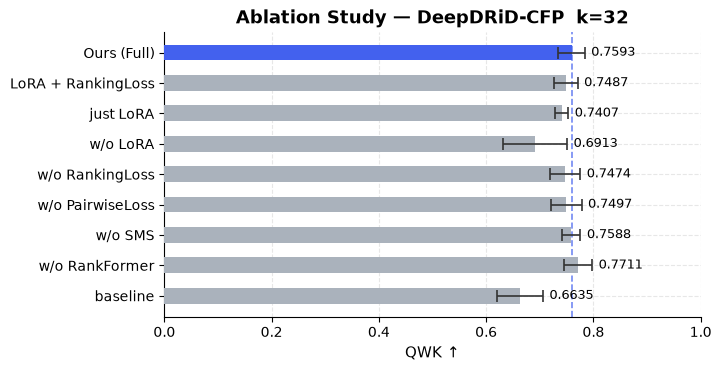

Saved → /home/user/Documents/Mohammadi/workspace/results/figures/ablation_qwk.pdf


In [23]:
# ── 7d · Ablation Study Table & Plot ─────────────────────────────────────────
# Table: mean ± std over seeds at one selected k.
# Plot : horizontal QWK bar chart matching the reference ablation figure.

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.30,
    'grid.linestyle': '--',
})

# Reference figure is for CFP at k=16 and uses QWK.
ABLATION_MOD_PLOT = 'CFP'
ABLATION_K_PLOT = 32
ABLATION_METRIC_PLOT = 'qwk'

# Set this to None to plot every variant in ABLATIONS.
# The three entries below reproduce the reference figure.
ABLATION_VARIANTS_TO_PLOT = [
    'Ours (Full)',
    'baseline',
    'w/o RankFormer',
    'w/o SMS',
    'w/o PairwiseLoss',
    'w/o RankingLoss',
    'w/o LoRA',
    'just LoRA',
    'LoRA + RankingLoss'
]

if df_ablation.empty:
    print('No ablation results yet — run Section 5c first.')
else:
    df_abl_agg = aggregate(
        df_ablation,
        ['Variant', 'Modality', 'k']
    )

    # Restrict the table to the selected modality and k.
    table = df_abl_agg[
        (df_abl_agg['Modality'] == ABLATION_MOD_PLOT) &
        (df_abl_agg['k'] == ABLATION_K_PLOT)
    ].copy()

    if ABLATION_VARIANTS_TO_PLOT is not None:
        table = table[
            table['Variant'].isin(ABLATION_VARIANTS_TO_PLOT)
        ].copy()

    # Preserve the requested display order, with Ours (Full) last in the plot.
    preferred_order = [
        v for v in (ABLATION_VARIANTS_TO_PLOT or list(ABLATIONS.keys()))
        if v in table['Variant'].tolist()
    ]

    table['_order'] = table['Variant'].map(
        {v: i for i, v in enumerate(preferred_order)}
    )
    table = table.sort_values('_order').drop(columns='_order')

    if table.empty:
        print(
            f'No ablation data found for '
            f'{ABLATION_MOD_PLOT}, k={ABLATION_K_PLOT}.'
        )
    else:
        # ── Table ────────────────────────────────────────────────────────────
        display_cols = [
            'Variant',
            'qwk', 'mae', 'f1', 'auc', 'acc', 'los'
        ]
        display_cols = [c for c in display_cols if c in table.columns]

        print(
            f'Ablation Study — {DATASET}-{ABLATION_MOD_PLOT}, '
            f'k={ABLATION_K_PLOT} (mean ± std over seeds)'
        )
        print('=' * 90)
        display(table[display_cols].reset_index(drop=True))

        # Save the selected-k table.
        table[display_cols].to_csv(
            RESULTS / 'ablation_results_k16.csv',
            index=False
        )

        # ── Horizontal QWK plot ──────────────────────────────────────────────
        metric = ABLATION_METRIC_PLOT
        mean_col = f'{metric}_mean'
        std_col = f'{metric}_std'

        plot_df = table[['Variant', mean_col, std_col]].copy()

        # Put Ours (Full) at the bottom, as in the reference figure.
        plot_order = [
            v for v in plot_df['Variant'].tolist()
            if v != 'Ours (Full)'
        ]
        if 'Ours (Full)' in plot_df['Variant'].tolist():
            plot_order.append('Ours (Full)')

        plot_df = (
            plot_df.set_index('Variant')
                   .loc[plot_order]
                   .reset_index()
        )

        y = np.arange(len(plot_df))
        means = plot_df[mean_col].astype(float).to_numpy()
        stds = plot_df[std_col].astype(float).to_numpy()

        # Grey for ablations, blue for the full model.
        colors = [
            '#4361EE' if v == 'Ours (Full)' else '#AAB2BC'
            for v in plot_df['Variant']
        ]

        fig, ax = plt.subplots(
            figsize=(7.1, 3.6),
            constrained_layout=True
        )

        ax.barh(
            y, means,
            xerr=stds,
            color=colors,
            edgecolor='none',
            height=0.52,
            capsize=4,
            error_kw={
                'elinewidth': 1.2,
                'capthick': 1.2,
                'ecolor': '#333333',
            },
            zorder=3,
        )

        # Reference line at the full-model QWK.
        full_rows = plot_df[plot_df['Variant'] == 'Ours (Full)']
        if not full_rows.empty:
            full_qwk = float(full_rows[mean_col].iloc[0])
            ax.axvline(
                full_qwk,
                color='#4361EE',
                linestyle='--',
                linewidth=1.2,
                alpha=0.75,
                zorder=2
            )

        # Numeric labels to the right of each bar.
        x_max = max(1.0, float(np.max(means + stds)) + 0.10)
        for yi, mean, std in zip(y, means, stds):
            ax.text(
                mean + std + 0.012,
                yi,
                f'{mean:.4f}',
                va='center',
                ha='left',
                fontsize=9
            )

        ax.set_yticks(y)
        ax.set_yticklabels(plot_df['Variant'], fontsize=10)
        ax.set_xlabel('QWK ↑', fontsize=11)
        ax.set_xlim(0, min(1.0, x_max))
        ax.grid(axis='x', zorder=0)

        ax.set_title(
            f'Ablation Study — {DATASET}-{ABLATION_MOD_PLOT}  '
            f'k={ABLATION_K_PLOT}',
            fontsize=13,
            fontweight='bold'
        )

        plt.savefig(
            FIGURES / 'ablation_qwk.pdf',
            bbox_inches='tight',
            dpi=300
        )
        plt.show()
        print(f'Saved → {FIGURES / "ablation_qwk.pdf"}')


### 7e · Radar / Spider Chart — Per-Metric Overview at k=16

Ablation Study — DeepDRiD-CFP (mean over seeds)


,Variant,k,qwk_mean,mae_mean,f1_mean,auc_mean,acc_mean,los_mean
0,LoRA + RankingLoss,-1,0.866545,0.366667,0.601607,0.885221,0.682500,0.990000
1,LoRA + RankingLoss,0,0.011518,1.254167,0.089695,0.526201,0.216667,0.948333
2,LoRA + RankingLoss,1,0.438156,0.962500,0.306489,0.655511,0.363333,0.970833
3,LoRA + RankingLoss,2,0.461104,0.926667,0.308968,0.709275,0.330000,0.947500
4,LoRA + RankingLoss,4,0.537968,0.855000,0.352553,0.730481,0.406667,0.950833
5,LoRA + RankingLoss,8,0.696922,0.675000,0.455903,0.788567,0.511667,0.972500
6,LoRA + RankingLoss,16,0.714653,0.606667,0.481735,0.813483,0.540000,0.970833
7,LoRA + RankingLoss,32,0.748662,0.564167,0.513327,0.822058,0.570833,0.978333
8,Ours (Full),-1,0.869783,0.363333,0.623192,0.887887,0.686667,1.000000
9,Ours (Full),0,0.023142,1.815000,0.096982,0.548037,0.176667,0.952500


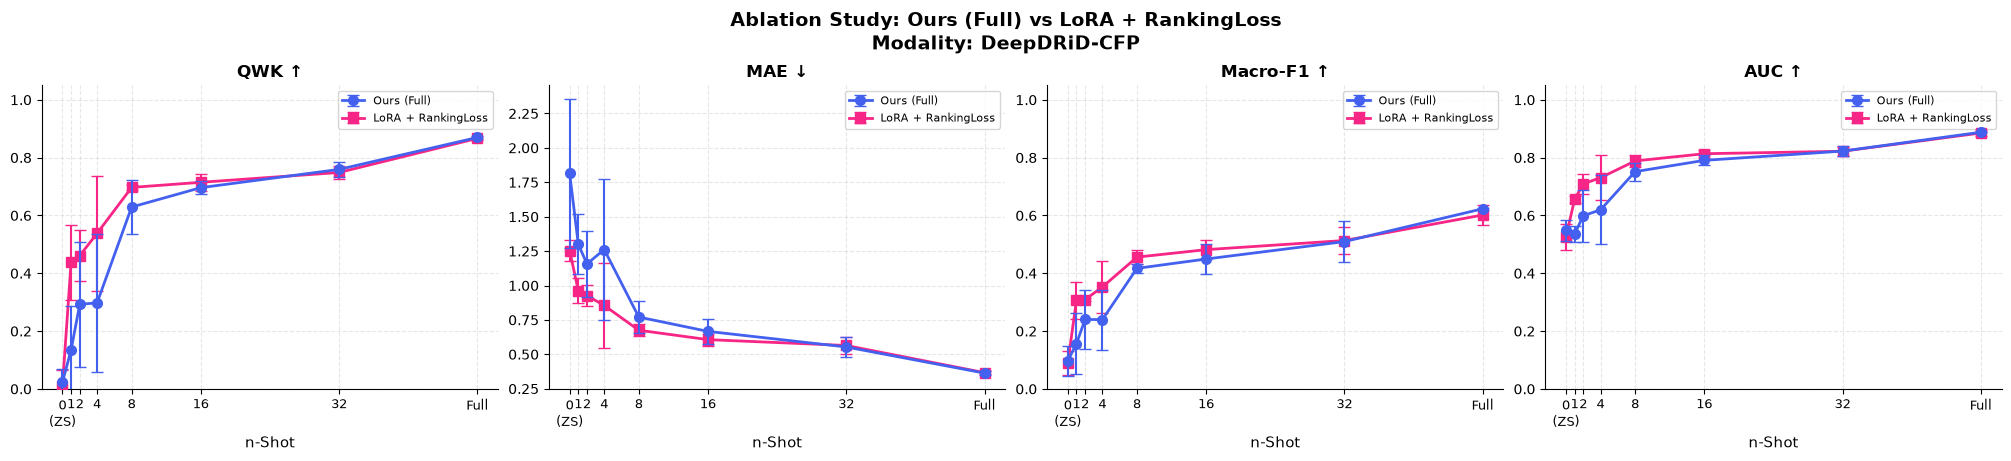

Saved → /home/user/Documents/Mohammadi/workspace/results/figures/ablation_full_vs_LoRA_+_RankingLoss_kshot.pdf


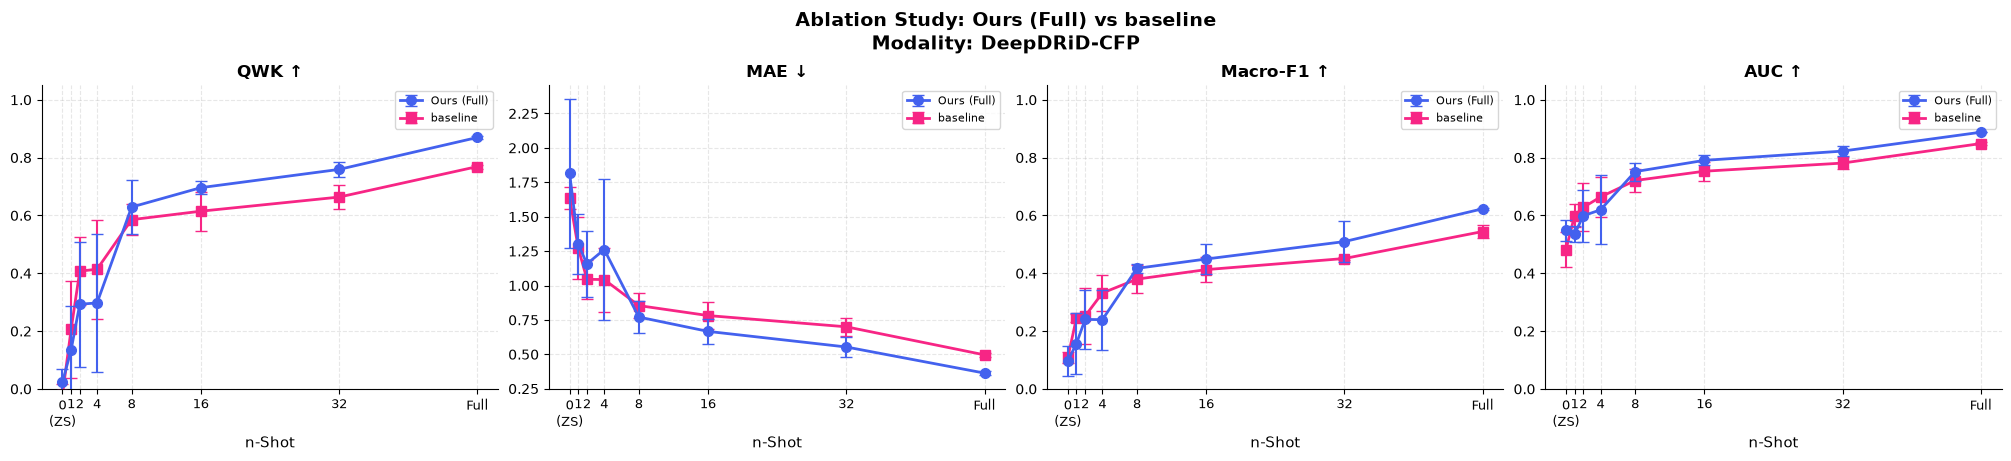

Saved → /home/user/Documents/Mohammadi/workspace/results/figures/ablation_full_vs_baseline_kshot.pdf


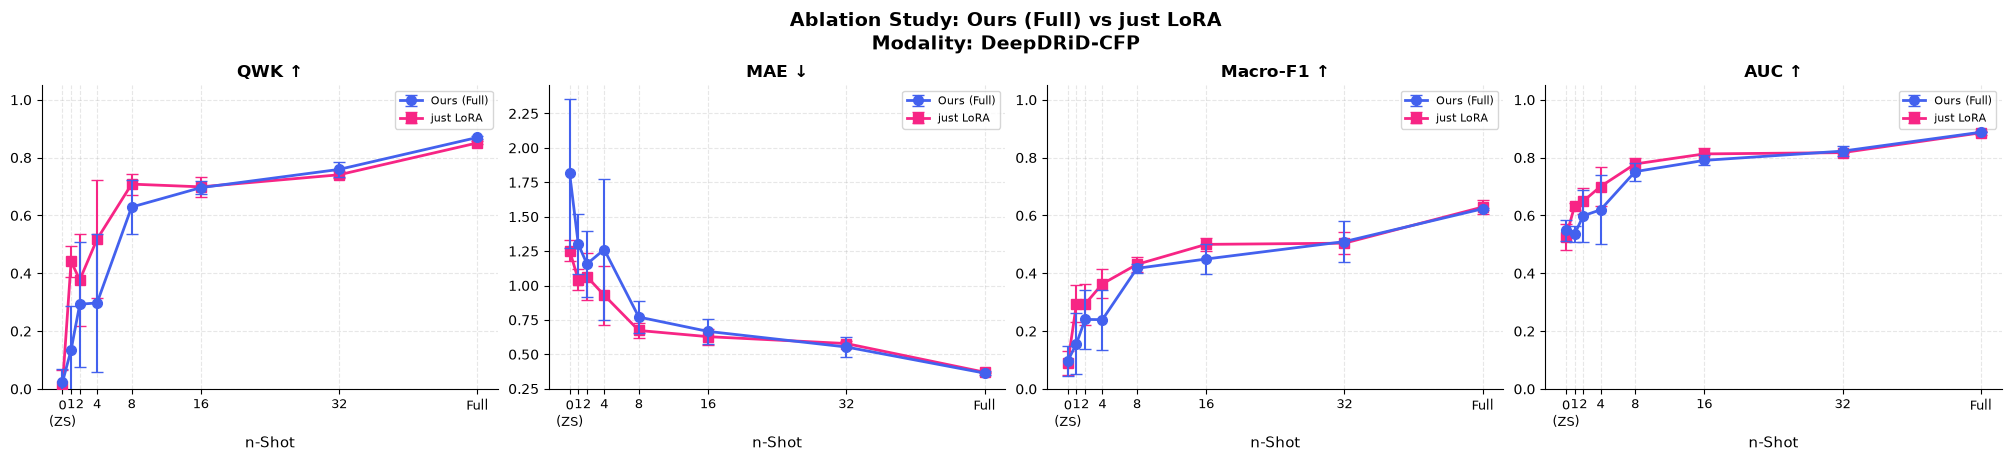

Saved → /home/user/Documents/Mohammadi/workspace/results/figures/ablation_full_vs_just_LoRA_kshot.pdf


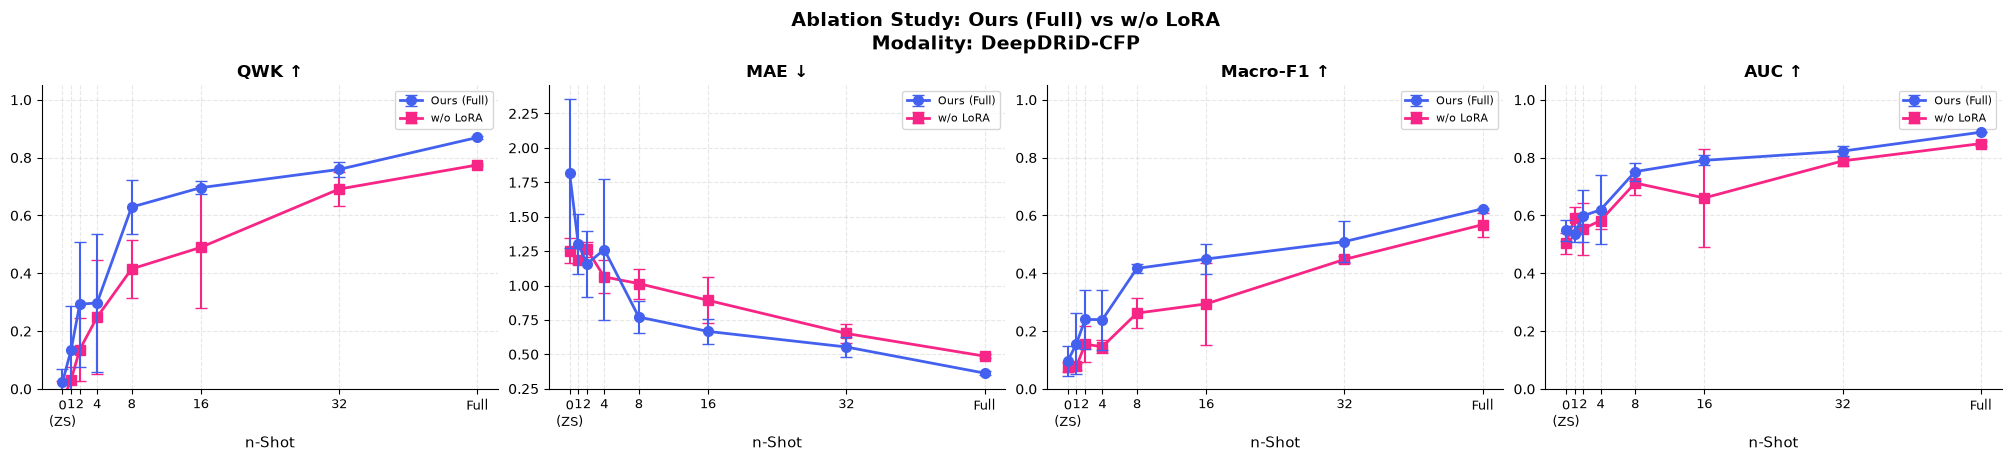

Saved → /home/user/Documents/Mohammadi/workspace/results/figures/ablation_full_vs_w_o_LoRA_kshot.pdf


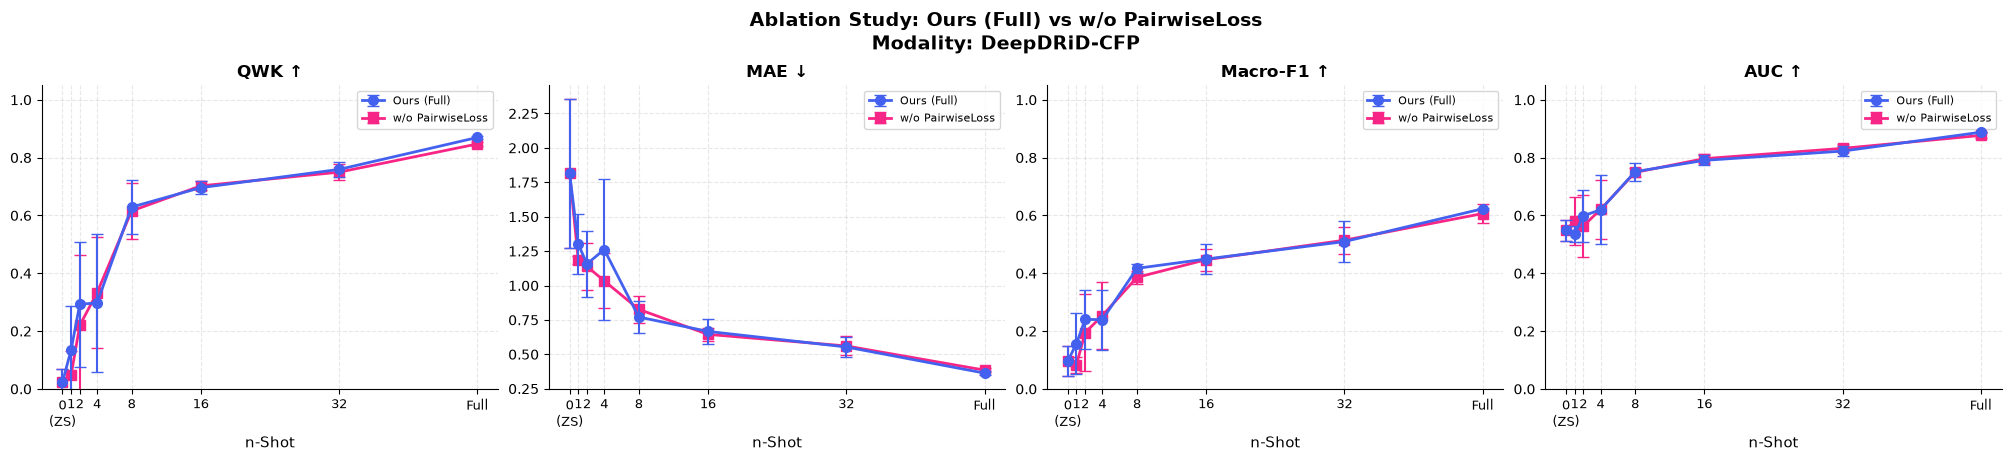

Saved → /home/user/Documents/Mohammadi/workspace/results/figures/ablation_full_vs_w_o_PairwiseLoss_kshot.pdf


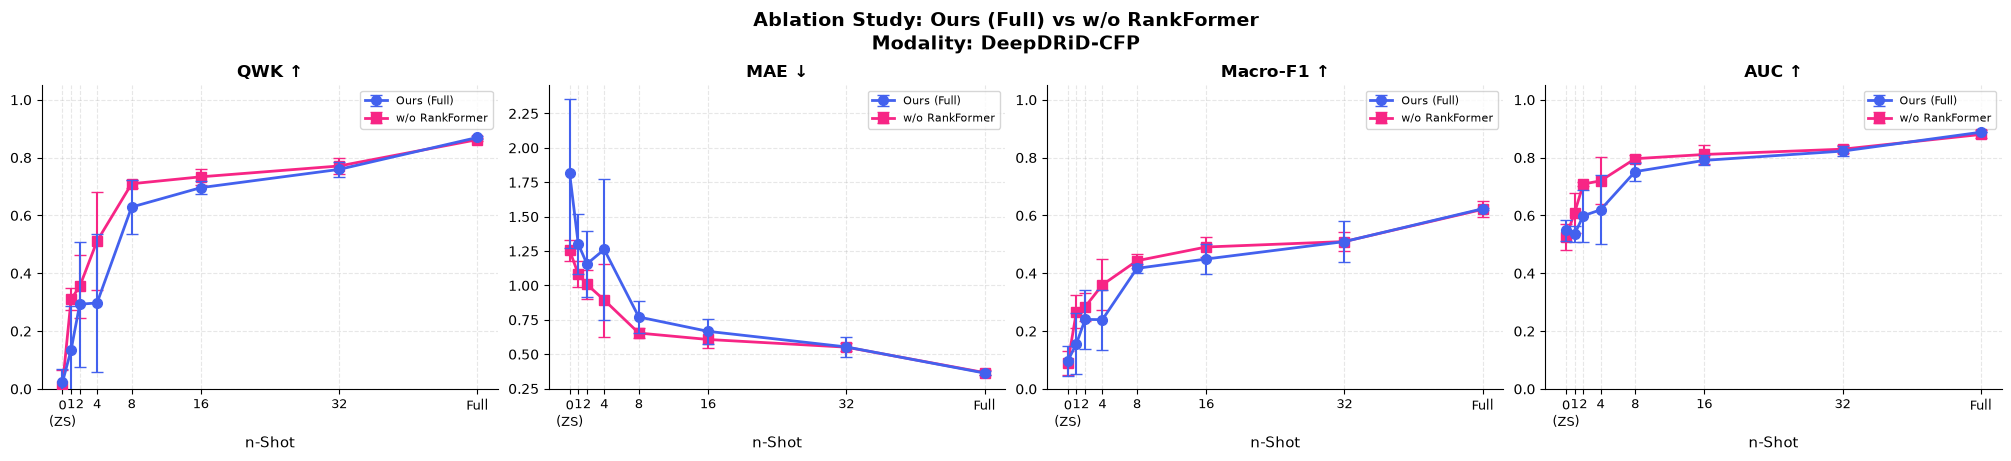

Saved → /home/user/Documents/Mohammadi/workspace/results/figures/ablation_full_vs_w_o_RankFormer_kshot.pdf


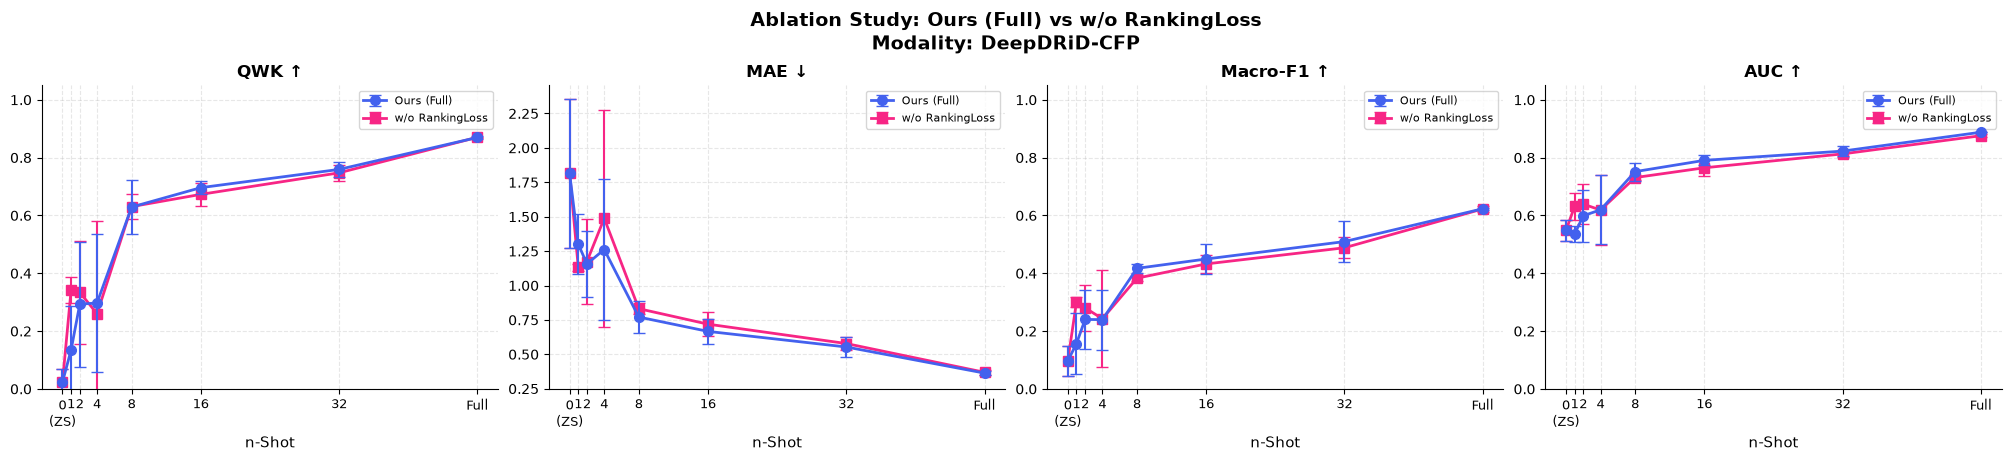

Saved → /home/user/Documents/Mohammadi/workspace/results/figures/ablation_full_vs_w_o_RankingLoss_kshot.pdf


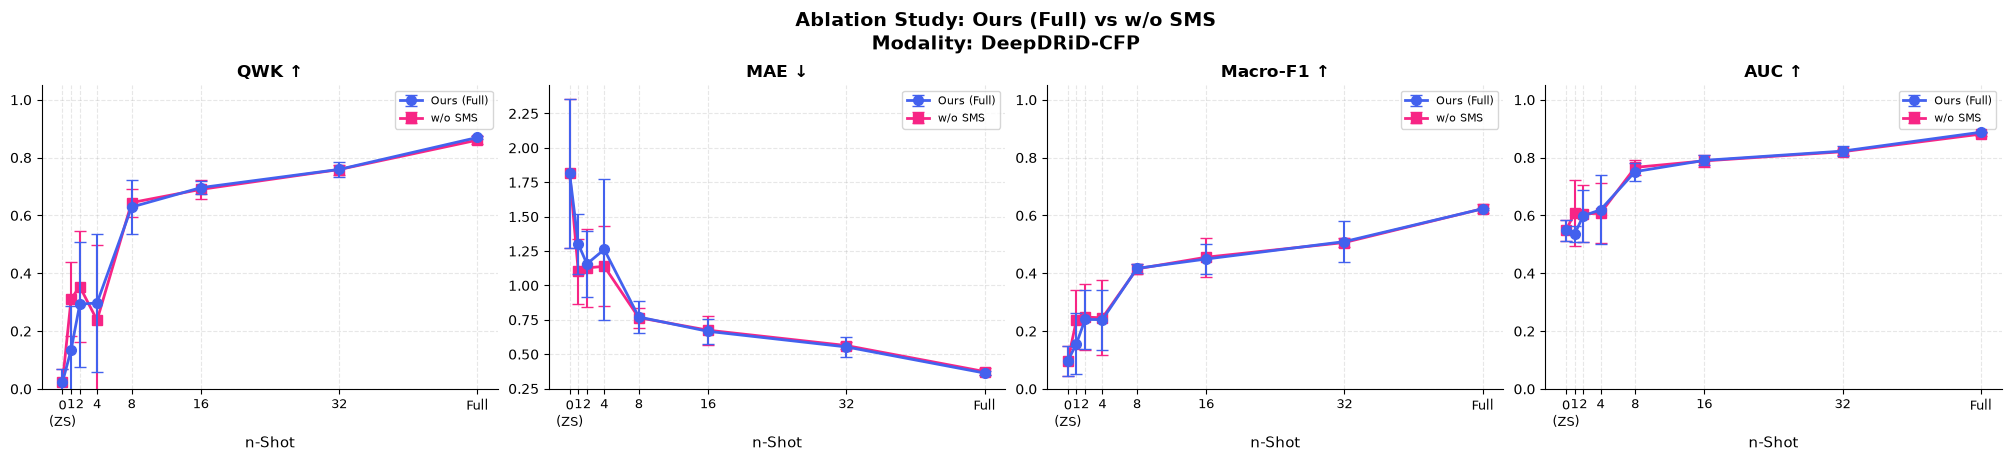

Saved → /home/user/Documents/Mohammadi/workspace/results/figures/ablation_full_vs_w_o_SMS_kshot.pdf


In [16]:
# ── Style ─────────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--',
})

if not df_ablation.empty:

    # ── Aggregate results ─────────────────────────────────────────────────
    df_abl_agg = aggregate(
        df_ablation,
        ['Variant', 'Modality', 'k']
    )

    # ── Save/display table ─────────────────────────────────────────────────
    display_cols = (
        ['Variant', 'k'] +
        [m for m in df_abl_agg.columns if m.endswith('_mean')]
    )

    print('Ablation Study — DeepDRiD-CFP (mean over seeds)')
    print('=' * 80)

    display(
        df_abl_agg[display_cols]
        .sort_values(['Variant', 'k'])
        .head(50)
    )

    df_abl_agg.to_csv(
        RESULTS / 'ablation_results.csv',
        index=False
    )

    # ── Plot settings ─────────────────────────────────────────────────────
    PLOT_METRICS = ['qwk', 'mae', 'f1', 'auc']
    PLOT_LABELS = ['QWK ↑', 'MAE ↓', 'Macro-F1 ↑', 'AUC ↑']

    full_variant = 'Ours (Full)'

    # All variants in the ablation results
    all_variants = (
        df_abl_agg['Variant']
        .dropna()
        .unique()
        .tolist()
    )

    # Only actual ablations, excluding Ours (Full)
    ablation_variants = [
        v for v in all_variants
        if v != full_variant
    ]

    # ── Create one figure per ablation ────────────────────────────────────
    for ablation_variant in ablation_variants:

        # Get Ours (Full)
        full_data = df_abl_agg[
            (df_abl_agg['Variant'] == full_variant) &
            (df_abl_agg['Modality'] == ABLATION_MOD)
        ].assign(k_plot=lambda x: np.where(x['k'] == -1, 48, x['k'])).sort_values('k_plot')

        # Get this specific ablation
        ablation_data = df_abl_agg[
            (df_abl_agg['Variant'] == ablation_variant) &
            (df_abl_agg['Modality'] == ABLATION_MOD)
        ].assign(k_plot=lambda x: np.where(x['k'] == -1, 48, x['k'])).sort_values('k_plot')

        # Skip if either side is missing
        if full_data.empty or ablation_data.empty:
            print(
                f'Skipping {ablation_variant}: '
                f'missing Full or ablation results.'
            )
            continue

        # ── Four metric panels ────────────────────────────────────────────
        fig, axes = plt.subplots(
            1,
            len(PLOT_METRICS),
            figsize=(20, 4.5),
            constrained_layout=True
        )

        axes = np.atleast_1d(axes)

        for ax, metric, label in zip(
            axes,
            PLOT_METRICS,
            PLOT_LABELS
        ):

            mean_col = f'{metric}_mean'
            std_col = f'{metric}_std'

            if mean_col not in df_abl_agg.columns:
                continue

            # ==============================================================
            # Ours (Full)
            # ==============================================================
            full_mu = full_data[mean_col].values

            if std_col in full_data.columns:
                full_std = full_data[std_col].values
            else:
                full_std = None

            full_k = full_data['k'].values
            full_k_plot = np.where(full_k == -1, 48, full_k)

            ax.errorbar(
                full_k_plot,
                full_mu,
                yerr=full_std,
                marker='o',
                color='#4361EE',
                linewidth=2,
                markersize=7,
                capsize=4,
                elinewidth=1.5,
                label='Ours (Full)',
                zorder=10
            )

            # ==============================================================
            # Specific Ablation
            # ==============================================================
            abl_mu = ablation_data[mean_col].values

            if std_col in ablation_data.columns:
                abl_std = ablation_data[std_col].values
            else:
                abl_std = None

            abl_k = ablation_data['k'].values
            abl_k_plot = np.where(abl_k == -1, 48, abl_k)

            ax.errorbar(
                abl_k_plot,
                abl_mu,
                yerr=abl_std,
                marker='s',
                color='#F72585',
                linewidth=2,
                markersize=7,
                capsize=4,
                elinewidth=1.5,
                label=ablation_variant,
                zorder=9
            )

            # ── Titles ───────────────────────────────────────────────────
            ax.set_title(
                label,
                fontsize=12,
                fontweight='bold'
            )

            ax.set_xlabel(
                'n-Shot',
                fontsize=11
            )

            # ── X-axis ───────────────────────────────────────────────────
            xticks_pos = [48 if k == -1 else k for k in ABLATION_K_SHOTS]
            ax.set_xticks(xticks_pos)

            ax.set_xticklabels(
                [
                    str(k) if k > 0
                    else '0\n(ZS)' if k == 0
                    else 'Full'
                    for k in ABLATION_K_SHOTS
                ],
                fontsize=9
            )

            # ── Y-axis ───────────────────────────────────────────────────
            if metric in ('qwk', 'f1', 'auc', 'acc'):
                ax.set_ylim(0, 1.05)

            # ── Legend ───────────────────────────────────────────────────
            ax.legend(
                fontsize=8,
                framealpha=0.8
            )

        # ── Overall title ─────────────────────────────────────────────────
        fig.suptitle(
            f'Ablation Study: Ours (Full) vs {ablation_variant}\n'
            f'Modality: DeepDRiD-{ABLATION_MOD}',
            fontsize=14,
            fontweight='bold'
        )

        # ── Safe filename ─────────────────────────────────────────────────
        safe_variant = (
            ablation_variant
            .replace(' ', '_')
            .replace('(', '')
            .replace(')', '')
            .replace('/', '_')
            .replace('\\', '_')
            .replace(':', '')
        )

        output_path = (
            FIGURES /
            f'ablation_full_vs_{safe_variant}_kshot.pdf'
        )
        output_path_png = (
            FIGURES /
            f'ablation_full_vs_{safe_variant}_kshot.png'
        )

        plt.savefig(
            output_path,
            bbox_inches='tight',
            dpi=300
        )
        plt.savefig(
            output_path_png,
            bbox_inches='tight',
            dpi=300
        )

        plt.show()

        print(f'Saved → {output_path}')

else:
    print('No ablation results yet — run Section 5c first.')

### 7f · Training Dynamics (Loss & Validation QWK vs. Epoch)

For this plot, enable Lightning CSV logging during training by setting `logger=True` in `run_experiment()` and then reading the `metrics.csv` file.

Loaded: /home/user/Documents/Mohammadi/workspace/lightning_logs/version_99/metrics.csv
['epoch', 'step', 'test_acc', 'test_auc', 'test_f1', 'test_los', 'test_mae', 'test_qwk', 'train_loss', 'val_acc', 'val_auc', 'val_f1', 'val_los', 'val_mae', 'val_qwk']


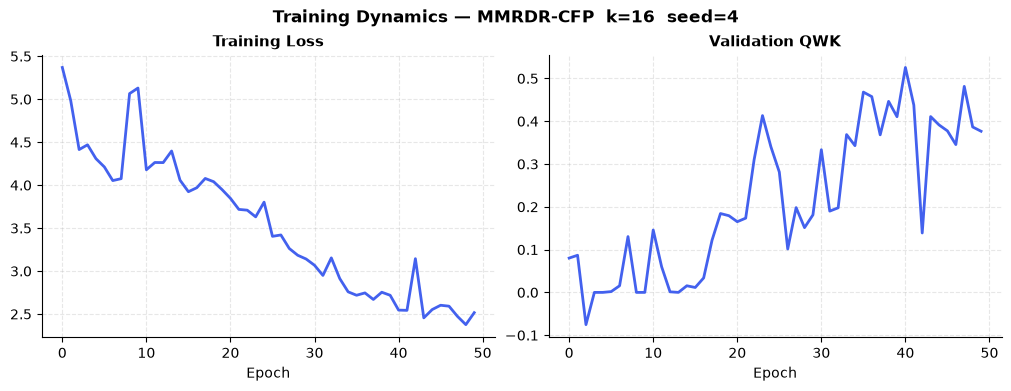

In [17]:
# Reads Lightning's default CSV logger output if available
DYNAMICS_MOD  = 'CFP'
DYNAMICS_K    = 16
DYNAMICS_SEED = 4
VARIANT_SLUG  = 'Ours_Full_'

lightning_logs = ROOT / 'lightning_logs'

if lightning_logs.exists():
    versions = sorted(lightning_logs.glob('version_*/metrics.csv'))
    if versions:
        # Use the most recent version (last run)
        df_log = pd.read_csv(versions[-1])
        print(f'Loaded: {versions[-1]}')
        print(df_log.columns.tolist())

        fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)

        for col, ax, label in [
            ('train_loss', axes[0], 'Training Loss'),
            ('val_qwk',   axes[1], 'Validation QWK'),
        ]:
            if col in df_log.columns:
                sub = df_log[['epoch', col]].dropna()
                ax.plot(sub['epoch'], sub[col], color='#4361EE', linewidth=2)
                ax.set_xlabel('Epoch', fontsize=10)
                ax.set_title(label, fontsize=11, fontweight='bold')
                ax.spines[['top', 'right']].set_visible(False)

        fig.suptitle(f'Training Dynamics — MMRDR-{DYNAMICS_MOD}  k={DYNAMICS_K}  seed={DYNAMICS_SEED}',
                     fontsize=12, fontweight='bold')
        plt.savefig(FIGURES / 'training_dynamics.pdf', bbox_inches='tight', dpi=300)
        plt.savefig(FIGURES / 'training_dynamics.png', bbox_inches='tight', dpi=300)
        plt.show()
    else:
        print('No metrics.csv found in lightning_logs. Enable CSV logger to generate.')
else:
    print('lightning_logs/ not found. Skip this plot or enable CSV logging in run_experiment().')

## 9 · Quick Sanity Check (single forward pass)

Useful to confirm the model loads and runs before committing to a full sweep.

In [18]:
import torch.nn.functional as F

SANITY_MOD = 'CFP'
SANITY_K   = 4

cfg_path = MODALITIES[SANITY_MOD]['config']
cfg = load_config(cfg_path, [f'data.k_shot={SANITY_K}', 'data.seed=1'])

model = FewShotOrdinalRunner(cfg).to(DEVICE)
model.eval()

dummy = torch.randn(4, 3, 224, 224).to(DEVICE)
with torch.no_grad():
    img_f, txt_f = model(dummy)
    scale = model.clip_model.logit_scale.exp()
    sim   = scale * img_f @ txt_f.T
    probs = F.softmax(sim, dim=-1)
    preds = probs.argmax(dim=-1)

print(f'Image features shape : {img_f.shape}')
print(f'Text  features shape : {txt_f.shape}')
print(f'Similarity matrix    : {sim.shape}')
print(f'Probabilities        : {probs.round(decimals=4)}')
print(f'Predictions          : {preds.tolist()}')
print('\nSanity check passed!')

Trainable parameters: 27546545
Image features shape : torch.Size([4, 1024])
Text  features shape : torch.Size([5, 1024])
Similarity matrix    : torch.Size([4, 5])
Probabilities        : tensor([[0.1489, 0.1465, 0.3237, 0.0897, 0.2913],
        [0.1382, 0.1431, 0.3249, 0.0863, 0.3074],
        [0.1477, 0.1501, 0.3266, 0.0929, 0.2827],
        [0.1427, 0.1492, 0.3234, 0.0888, 0.2958]], device='cuda:0')
Predictions          : [2, 2, 2, 2]

Sanity check passed!
